# Flux: Net ecosystem exchange (NEE) (2004-2025)

# About this notebook

Overview of the net ecosystem exchange of CO2 (`NEE`) of CH-LAE, 2004 to 2025, from the merged
flux record `30_FLUX_POST-PROCESSING_CHAIN/99_FPPC_MERGED_2004-2026.09`. This notebook computes and
corrects nothing; it describes what the flux chain produced.

**Sign convention and units.** `NEE` is negative when the forest takes up CO2. Half-hourly values
are in µmol CO2 m⁻² s⁻¹; sums are in gC m⁻² (1 µmol m⁻² s⁻¹ over 30 minutes is 0.0216 gC m⁻²).

**Columns used**

- `NEE_L3.1_L3.3_CUT_50_QCF_gfXG` — `NEE` after all quality tests (flag 0 and 1), filtered at the
  median USTAR threshold (`CUT_50`) and gap-filled with XGBoost. **The main series of the dataset**
  and the one used throughout unless stated otherwise
- `NEE_L3.1_L3.3_CUT_50_QCF` — the same before gap-filling: the measured records
- `FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED` — `0` measured, `1` gap-filled
- `NEE_L3.1_L3.3_CUT_16_QCF_gfXG`, `..._CUT_84_...` — the other two USTAR scenarios, for the USTAR
  uncertainty
- `NEE_L3.1_L3.3_CUT_50_QCF_gfMDS` — gap-filled with MDS, for comparison only
- `NEE_L3.1_L3.3_CUT_50_QCF_gfXG_RANDUNC` — random uncertainty of each half-hour
- `GPP_NT_OF_CUT_50`, `RECO_NT_OF_CUT_50`, `GPP_DT_OF_CUT_50`, `RECO_DT_OF_CUT_50` — gross primary
  production and ecosystem respiration from the nighttime and the daytime partitioning
- `FLAG_FLUX_SOURCE` — the gas analyser of each half-hour: `75` LI-7500, `72` LI-7200

**Two gas analysers.** The record joins two analysers of different design. The open-path LI-7500
(`IRGA75`) measured from 2004; its CO2 flux is corrected for self-heating at Level 1.1. The
enclosed-path LI-7200 (`IRGA72`) measured from January 2016. The two ran in parallel until December
2017, and the merged record switches from the LI-7500 to the LI-7200 on 1 January 2016. *Gas
analyser phases* below lists all phases of the record, and *The two analysers in parallel* compares
them where both measured.

::: {.callout-important title="Read the analyser change before comparing years across 2016"}

A difference between the years before and after 2016 can come from the forest or from the change of
analyser. On the half-hours both analysers measured, the corrected LI-7500 agrees with the LI-7200
closely. But the LI-7500 misses many wet half-hours that the LI-7200 still measures, and gap-filling
fills these as if they were dry, with too much uptake. The annual `NEE` of 2004-2015 may therefore
show too much uptake, by up to 100 to 200 gC m⁻² per year in the parallel years. See *Issues* on the
documentation site and the sections on the parallel period and on the step at the change below.

:::

**Conventions used throughout**

- *Sums, not means.* Annual and monthly values are sums in gC m⁻², the quantity a carbon budget
  uses. Sums run over the gap-filled series, so the measured share of each year is reported before
  any statistic.
- *Uncertainty* follows Pastorello et al. (2020): the random part adds in quadrature over the year,
  the USTAR part is half the difference between the `CUT_84` and `CUT_16` sums.
- *Measured records* are used only where the point is the measurement itself: coverage, the light
  and temperature responses, and the comparison of the two analysers.

**Timestamps.** The record is stored on `TIMESTAMP_MIDDLE` at 30 minutes in CET (UTC+1), so a
record labelled `13:15` is the average over `13:00` to `13:30`.

</br>

# Settings

In [1]:
# Columns of the merged flux record (30_FLUX_POST-PROCESSING_CHAIN/99).
varname = 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG'  # the main series, used unless stated otherwise
varname_measured = 'NEE_L3.1_L3.3_CUT_50_QCF'  # the same before gap-filling
flagname = 'FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED'
SCENARIOS = {'CUT_16': 'NEE_L3.1_L3.3_CUT_16_QCF_gfXG',
             'CUT_50': 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG',
             'CUT_84': 'NEE_L3.1_L3.3_CUT_84_QCF_gfXG'}
varname_mds = 'NEE_L3.1_L3.3_CUT_50_QCF_gfMDS'
randunc = 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG_RANDUNC'
PARTITIONING = {'GPP_NT': 'GPP_NT_OF_CUT_50', 'RECO_NT': 'RECO_NT_OF_CUT_50',
                'GPP_DT': 'GPP_DT_OF_CUT_50', 'RECO_DT': 'RECO_DT_OF_CUT_50'}
sourcename = 'FLAG_FLUX_SOURCE'
SOURCE_LEGEND = {75: 'LI-7500 (open path, IRGA75)', 72: 'LI-7200 (enclosed path, IRGA72)'}
# Measured drivers in the same file, for the light and temperature responses.
SW_IN = 'SW_IN_T1_47_1_MEASURED'
TA = 'TA_T1_47_1_HOMOGENIZED_MEASURED'
DAYTIME, NIGHTTIME = 'DAYTIME', 'NIGHTTIME'

var = "NEE"  # name shown in plots
units = "µmol m-2 s-1"
units_sum = "gC m-2"
UMOL_TO_GC = 12.011 * 1e-6 * 1800  # umol CO2 m-2 s-1 over one half-hour -> gC m-2

# Period covered by the yearly statistics: the full years of the record. The record runs to
# 30 September 2026; 2026 is incomplete and appears only in the phase overview.
FIRST_YEAR = 2004
LAST_YEAR = 2025

# The phases of the record, as they enter the merged product. Dates are the first day of each phase
# (TIMESTAMP_MIDDLE); a phase ends where the next one begins. Sources: docs/Instrumentation.md,
# docs/L1.md and the setup table in docs/Yearly_Notes.md.
PHASES = [
    ('2004-01-01', 'LI-7500 only', 75,
     'open-path LI-7500; CO2 flux corrected for self-heating (Level 1.1)'),
    ('2016-01-01', 'LI-7200, LI-7500 in parallel', 72,
     'LI-7200 from 11 January 2016 (start-up data of 1 March to 25 May removed); the LI-7500 still '
     'measures and is compared below, but is not used in the product'),
    ('2017-12-13', 'LI-7200, first unit', 72,
     'LI-7500 removed on 12 December 2017; flow module failed 18 May to 7 June 2018'),
    ('2019-01-10', 'no LI-7200 flux', 72,
     'both LI-7200 units defective, then the LI-7500 as a stand-in (not in the product); '
     'the whole phase is gap-filled'),
    ('2019-03-20', 'LI-7200, second unit', 72,
     'second LI-7200 unit; raw data of 13 December 2021 to 7 February 2022 cannot be converted'),
    ('2023-03-13', 'LI-7200, inlet moved', 72,
     'analyser moved on the boom, which changed its separation from the sonic anemometer'),
    ('2025-12-02', 'LI-7200, recalibrated unit', 72,
     'a freshly calibrated LI-7200 installed'),
]
RECORD_END = '2026-09-30 23:45'

# The two analysers ran in parallel from the start of the LI-7200 to the removal of the LI-7500.
PARALLEL = ('2016-01-11', '2017-12-12')

# Analysis parameters.
N_RECENT_YEARS = 10  # length of the recent period in the period sums
N_EXTREMES = 10  # number of days listed in the extremes tables
REFERENCE_START_YEAR = FIRST_YEAR  # reference period for all anomalies
REFERENCE_END_YEAR = LAST_YEAR
CUP_SMOOTHING_DAYS = 15  # running mean of daily NEE that defines the carbon uptake period
LIGHT_MONTHS = [6, 7, 8]  # full canopy, for the light response
LIMITS = (-60.0, 60.0)  # physical limits for the integrity check, umol m-2 s-1

# Input files. Data files live in the external (untracked) data folder, mirroring this repo.
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow\30_FLUX_POST-PROCESSING_CHAIN")
FILENAME = "99_FPPC_MERGED_2004-2026.09.parquet"
# The per-analyser records, for the parallel period only.
FILE_IRGA75 = r"IRGA75\99_FPPC_IRGA75_MERGED_2004-2017.parquet"
FILE_IRGA72 = r"IRGA72\99_FPPC_IRGA72_MERGED_2016-2026.09.parquet"

# Imports

In [2]:
import calendar
import importlib.metadata
import textwrap
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize
from scipy.stats import kendalltau, theilslopes

import diive as dv
from diive.core.io.files import save_parquet, load_parquet
from diive.core.plotting.cumulative import CumulativeYear
from diive.core.plotting.bar import LongtermAnomaliesYear

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)
version_diive = importlib.metadata.version("diive")
print(f"diive version: v{version_diive}")

diive version: v0.93.0


# Helpers

In [3]:
def per_year(s, how='mean'):
    """Aggregate `s` to one value per year, indexed by the year number instead of by a timestamp."""
    out = s.resample('YE').agg(how)
    out.index = out.index.year
    out.index.name = 'YEAR'
    return out


def per_year_month(s, how='mean', month_names=True):
    """Aggregate `s` to a table of YEAR (rows) by MONTH (columns)."""
    out = s.groupby([s.index.year, s.index.month]).agg(how).unstack()
    out.index.name = 'YEAR'
    if month_names:
        out.columns = [calendar.month_abbr[m] for m in out.columns]
    return out


def tabcap(text, width=100):
    """Print a table caption. Called by `styled`, so no table can be shown without one."""
    print(textwrap.fill(f"Table — {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure. Call after the last axes of that figure is drawn.

    A figure drawn with a layout engine makes room for a caption by itself. The figures pandas and
    diive build have no engine, and a caption placed in them lands on top of the tick labels. For
    those the figure is extended downwards by the height of the caption and every axes is moved up
    by the same amount, so the drawing keeps its size and position and the caption gets a free
    strip below it. `width` is the widest the caption may wrap, narrowed for a narrow figure.
    """
    # A fixed wrap width runs off the side of a narrow figure, so it is capped by how many
    # characters of this font size fit across the figure.
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    caption = textwrap.fill(f"Figure — {text}", width)
    # An engine that still lays the figure out at draw time can make room for a caption itself.
    # plt.tight_layout() does NOT leave one: it executes once and leaves a PlaceHolderLayoutEngine
    # that never runs again, so a caption handed to supxlabel there lands on top of the tick
    # labels. Those figures take the manual branch below.
    _engine = fig.get_layout_engine()
    if _engine is not None and type(_engine).__name__ != 'PlaceHolderLayoutEngine':
        fig.supxlabel(caption, fontsize=9, ha='left', x=0.005)
        return
    lines = len(caption.splitlines())
    extra = 0.17 * lines + 0.12  # inches, one caption line is about 0.17 in at fontsize 9
    width_in, height_in = fig.get_size_inches()
    fig.set_size_inches(width_in, height_in + extra)
    keep = height_in / (height_in + extra)  # the old figure as a fraction of the new one
    offset = extra / (height_in + extra)
    for ax in fig.axes:
        pos = ax.get_position()
        ax.set_position([pos.x0, offset + pos.y0 * keep, pos.width, pos.height * keep])
    fig.text(0.005, 0.01, caption, fontsize=9, ha='left', va='bottom')


def window(tsmid):
    """The averaging window of a 30MIN record stored on TIMESTAMP_MIDDLE, as text."""
    start = tsmid - pd.Timedelta('15min')
    end = tsmid + pd.Timedelta('15min')
    return f"{start:%d %b %Y}, {start:%H:%M} to {end:%H:%M}"


def styled(data, caption, fmt="{:.1f}", subset=None, cmap="RdYlBu_r", axis=0, center=False):
    """`data` as a table with a caption, fixed decimals and a colour scale over its values.

    The caption is printed above the table, so it is written as a sentence about what the table
    shows rather than as a title. `center` puts the midpoint of the colour scale at zero, and
    `axis=None` scales the colours across the whole table instead of column by column. The colour
    scale sets a text colour per cell, so the numbers stay readable in both the light and the dark
    version of the rendered page.
    """
    # Formats apply to numbers only, so text columns are dropped from the map. Without this a
    # table carrying a date or a label raises at render time, not at call time.
    numeric = [c for c in data.columns if pd.api.types.is_numeric_dtype(data[c])]
    fmt = {c: fmt for c in numeric} if isinstance(fmt, str) else {
        c: f for c, f in fmt.items() if c in numeric}
    tabcap(caption)
    styler = data.style.format(fmt, na_rep="-")
    if cmap is None:
        return styler
    limits = {}
    if center:
        values = data[subset] if subset is not None else data
        absmax = np.nanmax(np.abs(values.to_numpy(dtype=float)))
        limits = dict(vmin=-absmax, vmax=absmax)
    return styler.background_gradient(cmap=cmap, subset=subset, axis=axis,
                                      text_color_threshold=0.4, **limits)


def anomaly_bars(styler, column):
    """Draw in-cell bars for an anomaly column, in the colours of the anomaly plots."""
    return styler.bar(subset=[column], align='zero', color=['#42A5F5', '#EF5350'])


def trend(yearly):
    """Theil-Sen slope per decade of a yearly series, with its 95 % interval and Kendall's tau.

    Theil-Sen rather than least squares because a single extreme year does not move it, and
    Kendall's tau because it tests a monotonic trend without assuming normal residuals.
    """
    years = yearly.index.to_numpy(dtype=float)
    values = yearly.to_numpy(dtype=float)
    slope, intercept, low, high = theilslopes(values, years, alpha=0.95)
    tau, pvalue = kendalltau(years, values)
    return dict(slope=slope * 10, low=low * 10, high=high * 10, tau=tau, pvalue=pvalue,
                fit=pd.Series(intercept + slope * years, index=yearly.index))


def longest_spell(mask):
    """Length in days and start date of the longest run of True in a daily boolean series."""
    blocks = mask.ne(mask.shift()).cumsum()
    runs = mask[mask].groupby(blocks[mask]).size()
    if runs.empty:
        return 0, pd.NaT
    return int(runs.max()), mask.index[blocks == runs.idxmax()][0]


def year_axis(ax):
    """Integer year ticks. Matplotlib otherwise labels a numeric year axis with half-years."""
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    return ax


def to_gc(s):
    """Half-hourly NEE in umol m-2 s-1 summed to gC m-2 over whatever period `s` covers."""
    return s.sum() * UMOL_TO_GC


def phase_of(index):
    """The phase name of each timestamp in `index`."""
    starts = pd.to_datetime([p[0] for p in PHASES])
    pos = np.searchsorted(starts.to_numpy(), index.to_numpy(), side='right') - 1
    return pd.Series([PHASES[i][1] for i in pos], index=index)


def shade_phases(ax, alpha=0.08):
    """Shade the analyser phases behind a time axis and mark their boundaries."""
    colors = ['#1E88E5', '#43A047', '#FB8C00', '#9E9E9E', '#8E24AA', '#00ACC1', '#E53935']
    bounds = [pd.Timestamp(p[0]) for p in PHASES] + [pd.Timestamp(RECORD_END)]
    for i, (start, end) in enumerate(zip(bounds[:-1], bounds[1:])):
        ax.axvspan(start, end, color=colors[i % len(colors)], alpha=alpha, lw=0)
        ax.axvline(start, color='#616161', lw=0.6, ls=':')


def era(year):
    """The gas analyser of a calendar year in the merged record."""
    return 'LI-7500' if year < 2016 else 'LI-7200'

</br>

# Load data

In [4]:
df_full = load_parquet(filepath=Path(DATADIR) / FILENAME)
print(f"Columns: {df_full.shape[1]}")
print(f"Range:   {df_full.index[0]} -> {df_full.index[-1]} ({len(df_full):,} records)")

# The yearly statistics cover FIRST_YEAR to LAST_YEAR; the phase overview uses the full record.
df = df_full.loc[str(FIRST_YEAR):str(LAST_YEAR)].copy()
series = df[varname].copy()
series_measured = df[varname_measured].copy()
xlabel = f"{var} ({units})"
print(f"Kept {FIRST_YEAR}-{LAST_YEAR}: {len(df):,} records")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\99_FPPC_MERGED_2004-2026.09.parquet (0.347 seconds).

Columns: 204
Range:   2004-01-01 00:15:00 -> 2026-09-30 23:45:00 (398,832 records)
Kept 2004-2025: 385,728 records


## Integrity checks

In [5]:
# The overview describes the record, so it starts by checking what everything below assumes: one
# continuous 30MIN record without duplicates, complete main series within physical limits, complete
# years, and the analyser codes where the merge put them.
_issues = []
if df_full.index.duplicated().any():
    _issues.append("duplicate timestamps")
if not (df_full.index.to_series().diff().dropna() == pd.Timedelta('30min')).all():
    _issues.append("index gaps")
for _c in [varname, *SCENARIOS.values(), varname_mds, randunc, PARTITIONING['GPP_NT'],
           PARTITIONING['RECO_NT']]:
    if df[_c].isna().any():
        _issues.append(f"{_c}: {int(df[_c].isna().sum())} missing values")
if ((series < LIMITS[0]) | (series > LIMITS[1])).any():
    _issues.append(f"values outside {LIMITS}")
_counts = series.groupby(series.index.year).size()
_short = {y: int(n) for y, n in _counts.items() if n != (17568 if calendar.isleap(y) else 17520)}
if _short:
    _issues.append(f"incomplete years: {_short}")
if set(df[flagname].unique()) - {0, 1}:
    _issues.append(f"unknown fill flags: {sorted(set(df[flagname].unique()))}")
# Measured records are exactly the records the fill flag marks as measured.
if not (series_measured.notna() == df[flagname].eq(0)).all():
    _issues.append("fill flag and measured records disagree")
if not ((df_full[sourcename] == 75) == (df_full.index < '2016-01-01')).all():
    _issues.append("analyser codes not where the merge put them")

print(f"records: {len(df):,}   years: {FIRST_YEAR}-{LAST_YEAR}")
print(f"range:   {series.min():.1f} to {series.max():.1f} {units}")
assert not _issues, "the record is not what this overview assumes: " + "; ".join(_issues)
print("Integrity checks passed.")

records: 385,728   years: 2004-2025
range:   -50.0 to 49.9 µmol m-2 s-1
Integrity checks passed.


## Derived series

In [6]:
# Daily sums of the main series and of its parts, with the measured share of each day, derived once.
# `daily` holds gC m-2 per day; the partitioning columns are positive by construction.
daily = pd.DataFrame({
    'NEE': series.resample('D').sum() * UMOL_TO_GC,
    'measured (%)': df[flagname].eq(0).resample('D').mean() * 100,
    'GPP_NT': df[PARTITIONING['GPP_NT']].resample('D').sum() * UMOL_TO_GC,
    'RECO_NT': df[PARTITIONING['RECO_NT']].resample('D').sum() * UMOL_TO_GC,
})
is_day = df[DAYTIME].eq(1)
print(f"Measured records: {series_measured.notna().sum():,} of {len(series):,} "
      f"({series_measured.notna().mean() * 100:.1f} %)")
daily.describe().round(2)

Measured records: 160,180 of 385,728 (41.5 %)


,NEE,measured (%),GPP_NT,RECO_NT
count,8036.00,8036.00,8036.00,8036.00
mean,-0.33,41.53,4.17,3.84
std,3.27,24.97,4.11,1.74
min,-19.69,0.00,-8.93,0.00
25%,-2.72,22.92,0.75,2.71
50%,0.05,41.67,3.38,3.77
75%,2.20,60.42,7.43,4.95
max,12.76,100.00,19.69,12.61


</br>

# Gas analyser phases

The record has seven phases. The analyser changed once, on 1 January 2016; the later phases are
changes within the LI-7200 record: a different unit, a gap, a moved inlet, a recalibrated unit.

## 📋 Table: the phases of the record

In [7]:
_bounds = [pd.Timestamp(p[0]) for p in PHASES] + [pd.Timestamp(RECORD_END) + pd.Timedelta('15min')]
_rows = []
for (start, name, code_, note), end in zip(PHASES, _bounds[1:]):
    _sel = df_full.loc[start:end - pd.Timedelta('30min')]
    _meas = _sel[varname_measured].notna()
    _rows.append({
        'phase': name, 'from': f"{pd.Timestamp(start):%d %b %Y}",
        'to': f"{end - pd.Timedelta('1D'):%d %b %Y}",
        'days': (end - pd.Timestamp(start)).days, 'analyser in the product': SOURCE_LEGEND[code_],
        'measured (%)': 100 * _meas.mean(),
        'measured, day (%)': 100 * _meas[_sel[DAYTIME] == 1].mean(),
        'measured, night (%)': 100 * _meas[_sel[NIGHTTIME] == 1].mean(),
        'what changed': note})
phases = pd.DataFrame(_rows).set_index('phase')
display(styled(phases, caption="the phases of the NEE record with the analyser the merged product uses "
                               "in each, and the share of measured half-hours by day and by night. "
                               "The measured share after all quality tests and the USTAR filter is "
                               "what the gap-filling learns from",
               fmt={'days': "{:.0f}", 'measured (%)': "{:.1f}", 'measured, day (%)': "{:.1f}",
                    'measured, night (%)': "{:.1f}"},
               subset=['measured (%)', 'measured, day (%)', 'measured, night (%)'], cmap='Blues'))

Table — the phases of the NEE record with the analyser the merged product uses in each, and the
share of measured half-hours by day and by night. The measured share after all quality tests and the
USTAR filter is what the gap-filling learns from



,from,to,days,analyser in the product,measured (%),"measured, day (%)","measured, night (%)",what changed
phase,,,,,,,,
LI-7500 only,01 Jan 2004,31 Dec 2015,4383,"LI-7500 (open path, IRGA75)",38.0,47.7,28.3,open-path LI-7500; CO2 flux corrected for self-heating (Level 1.1)
"LI-7200, LI-7500 in parallel",01 Jan 2016,12 Dec 2017,712,"LI-7200 (enclosed path, IRGA72)",42.7,50.6,34.7,"LI-7200 from 11 January 2016 (start-up data of 1 March to 25 May removed); the LI-7500 still measures and is compared below, but is not used in the product"
"LI-7200, first unit",13 Dec 2017,09 Jan 2019,393,"LI-7200 (enclosed path, IRGA72)",43.1,51.6,35.0,LI-7500 removed on 12 December 2017; flow module failed 18 May to 7 June 2018
no LI-7200 flux,10 Jan 2019,19 Mar 2019,69,"LI-7200 (enclosed path, IRGA72)",0.0,0.0,0.0,"both LI-7200 units defective, then the LI-7500 as a stand-in (not in the product); the whole phase is gap-filled"
"LI-7200, second unit",20 Mar 2019,12 Mar 2023,1454,"LI-7200 (enclosed path, IRGA72)",46.9,56.6,37.3,second LI-7200 unit; raw data of 13 December 2021 to 7 February 2022 cannot be converted
"LI-7200, inlet moved",13 Mar 2023,01 Dec 2025,995,"LI-7200 (enclosed path, IRGA72)",51.0,59.4,42.3,"analyser moved on the boom, which changed its separation from the sonic anemometer"
"LI-7200, recalibrated unit",02 Dec 2025,30 Sep 2026,303,"LI-7200 (enclosed path, IRGA72)",47.6,58.6,35.9,a freshly calibrated LI-7200 installed


## 📊 Plot: the record and its phases

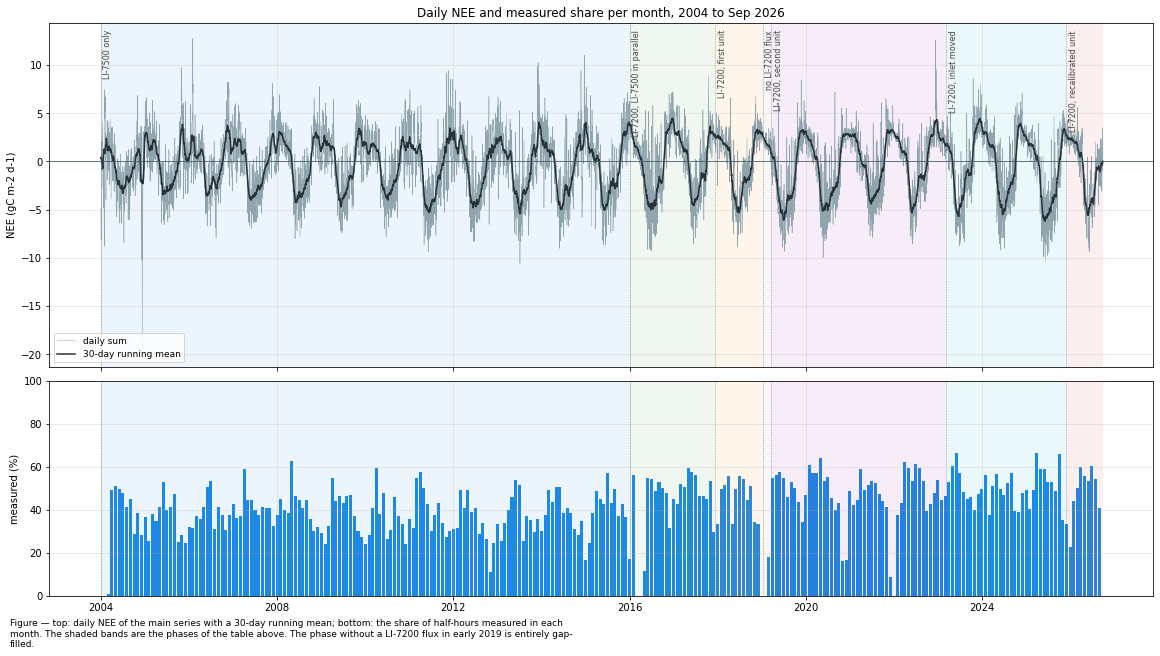

In [8]:
fig, axs = plt.subplots(2, 1, figsize=(16, 9), dpi=72, sharex=True, layout="constrained",
                        height_ratios=[1.6, 1])
_d = df_full[varname].resample('D').sum() * UMOL_TO_GC
axs[0].plot(_d.index, _d, color='#90A4AE', lw=0.5, label="daily sum")
axs[0].plot(_d.index, _d.rolling(30, center=True, min_periods=15).mean(), color='#263238', lw=1.5,
            label="30-day running mean")
axs[0].axhline(0, color='#455A64', lw=0.8)
axs[0].set_ylabel(f"NEE ({units_sum} d-1)")
_m = df_full[varname_measured].notna().resample('MS').mean() * 100
axs[1].bar(_m.index, _m, width=25, color='#1E88E5')
axs[1].set_ylabel("measured (%)")
axs[1].set_ylim(0, 100)
for _ax in axs:
    shade_phases(_ax)
    _ax.grid(alpha=0.3)
_ymax = axs[0].get_ylim()[1]
for start, name, _, _ in PHASES:
    axs[0].text(pd.Timestamp(start) + pd.Timedelta('20D'), _ymax * 0.95, name, rotation=90,
                va='top', ha='left', fontsize=8, color='#424242')
axs[0].legend(loc='lower left', fontsize=9)
axs[0].set_title(f"Daily NEE and measured share per month, {df_full.index[0]:%Y} to {df_full.index[-1]:%b %Y}")
figcap(fig, "top: daily NEE of the main series with a 30-day running mean; bottom: the share of "
            "half-hours measured in each month. The shaded bands are the phases of the table above. "
            "The phase without a LI-7200 flux in early 2019 is entirely gap-filled.")
fig.show()

## 📋 Table: half-hours per analyser and year

In [9]:
_src = df_full[sourcename].groupby(df_full.index.year).value_counts().unstack(fill_value=0)
_src.columns = [SOURCE_LEGEND[c] for c in _src.columns]
_src.index.name = 'YEAR'
display(styled(_src, caption="half-hours per year by the analyser the merged record takes them from",
               fmt="{:.0f}", cmap=None))

Table — half-hours per year by the analyser the merged record takes them from



,"LI-7500 (open path, IRGA75)","LI-7200 (enclosed path, IRGA72)"
YEAR,,
2004,17568,0
2005,17520,0
2006,17520,0
2007,17520,0
2008,17568,0
2009,17520,0
2010,17520,0
2011,17520,0
2012,17568,0


</br>

# Coverage

How much of each year was measured. Every sum below runs over the gap-filled series, so this says
how far each year rests on the measurement and how far on the model.

## 📋 Table: coverage per year

In [10]:
_meas = series_measured.notna()
coverage = pd.DataFrame({
    'analyser': [era(y) for y in range(FIRST_YEAR, LAST_YEAR + 1)],
    'measured (%)': per_year(_meas.astype(float), 'mean') * 100,
    'measured, day (%)': per_year(_meas.where(is_day).astype(float), 'mean') * 100,
    'measured, night (%)': per_year(_meas.where(~is_day).astype(float), 'mean') * 100,
}, index=range(FIRST_YEAR, LAST_YEAR + 1))
_filled = df[flagname].eq(1)
_blocks = _filled.ne(_filled.shift()).cumsum()[_filled]
_lengths = _filled[_filled].groupby(_blocks).size() / 48
_years = df.index[_filled].to_series().groupby(_blocks.to_numpy()).first().dt.year
coverage['longest gap (d)'] = pd.Series(_lengths.to_numpy(), index=_years.to_numpy()).groupby(level=0).max()
coverage.index.name = 'YEAR'
display(styled(coverage, caption="measured share of NEE per year, by day and by night, and the longest "
                                 "gap-filled run. Nighttime records are removed more often than "
                                 "daytime ones, mostly by the USTAR filter",
               fmt={'measured (%)': "{:.1f}", 'measured, day (%)': "{:.1f}",
                    'measured, night (%)': "{:.1f}", 'longest gap (d)': "{:.1f}"},
               subset=['measured (%)', 'measured, day (%)', 'measured, night (%)'], cmap='Blues'))

Table — measured share of NEE per year, by day and by night, and the longest gap-filled run.
Nighttime records are removed more often than daytime ones, mostly by the USTAR filter



,analyser,measured (%),"measured, day (%)","measured, night (%)",longest gap (d)
YEAR,,,,,
2004,LI-7500,31.8,41.4,22.4,90.5
2005,LI-7500,36.4,46.5,26.3,3.5
2006,LI-7500,38.4,47.3,29.6,2.9
2007,LI-7500,41.5,51.1,32.0,3.3
2008,LI-7500,41.5,51.2,31.9,3.0
2009,LI-7500,38.6,49.1,28.2,2.9
2010,LI-7500,36.3,45.3,27.4,8.7
2011,LI-7500,39.7,49.8,29.7,15.0
2012,LI-7500,33.9,43.6,24.4,21.9


## 📊 Plot: measured share per year and month

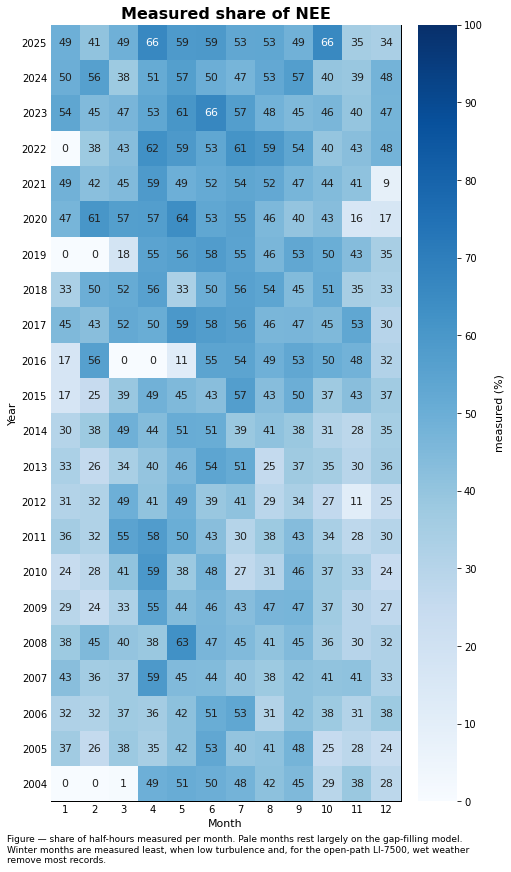

In [11]:
fig, ax = plt.subplots(figsize=(7, 12), dpi=72, layout="constrained")
_meas_pct = (series_measured.notna().astype(float) * 100).rename("measured (%)")
dv.plotting.HeatmapYearMonth(series=_meas_pct, agg='mean').plot(
    ax=ax, cmap="Blues", vmin=0, vmax=100, zlabel="measured (%)", show_values=True, cb_labelsize=10,
    format_style=dv.plotting.FormatStyle(title=f"Measured share of {var}", axlabel_fontsize=11,
                                         ticks_fontsize=10))
figcap(fig, "share of half-hours measured per month. Pale months rest largely on the gap-filling "
            "model. Winter months are measured least, when low turbulence and, for the open-path "
            "LI-7500, wet weather remove most records.")

</br>

# Annual sums

## 📋 Table: annual sums and their uncertainty

In [12]:
# Annual sums of the main series with the three uncertainty terms, the other USTAR scenarios and the
# MDS comparison. Random uncertainty adds in quadrature over the year; the USTAR term is half the
# difference between the CUT_84 and CUT_16 sums; the joint term combines the two.
yt = per_year(series, to_gc)
_scen = pd.DataFrame({k: per_year(df[c], to_gc) for k, c in SCENARIOS.items()})
_rand = per_year((df[randunc] * UMOL_TO_GC) ** 2, 'sum') ** 0.5
_ustar = (_scen['CUT_84'] - _scen['CUT_16']).abs() / 2
annual = pd.DataFrame({
    'analyser': [era(y) for y in yt.index],
    f"NEE ({units_sum})": yt,
    "random unc.": _rand,
    "USTAR unc.": _ustar,
    "joint unc.": (_rand ** 2 + _ustar ** 2) ** 0.5,
    "CUT_16": _scen['CUT_16'],
    "CUT_84": _scen['CUT_84'],
    "MDS": per_year(df[varname_mds], to_gc),
    "GPP (NT)": per_year(df[PARTITIONING['GPP_NT']], to_gc),
    "RECO (NT)": per_year(df[PARTITIONING['RECO_NT']], to_gc),
    "GPP (DT)": per_year(df[PARTITIONING['GPP_DT']], to_gc).where(lambda s: s != 0),
    "RECO (DT)": per_year(df[PARTITIONING['RECO_DT']], to_gc).where(lambda s: s != 0),
    "measured (%)": coverage['measured (%)'],
})
annual["rank (most uptake first)"] = annual[f"NEE ({units_sum})"].rank().astype(int)
annual.index.name = 'YEAR'
_fmt = {c: "{:.0f}" for c in annual.columns}
_fmt["measured (%)"] = "{:.1f}"
display(styled(annual, caption=f"annual sums in {units_sum}: NEE of the main series (XGBoost, CUT_50) with its "
                               f"random, USTAR and joint uncertainty at 1 sigma; NEE of the other two "
                               f"USTAR scenarios and of MDS; GPP and RECO from the nighttime (NT) and "
                               f"daytime (DT) partitioning. The daytime partitioning has no result for "
                               f"2004, when no shortwave radiation was measured",
               fmt=_fmt, subset=[f"NEE ({units_sum})"], cmap='RdBu_r', center=True))

Table — annual sums in gC m-2: NEE of the main series (XGBoost, CUT_50) with its random, USTAR and
joint uncertainty at 1 sigma; NEE of the other two USTAR scenarios and of MDS; GPP and RECO from the
nighttime (NT) and daytime (DT) partitioning. The daytime partitioning has no result for 2004, when
no shortwave radiation was measured



,analyser,NEE (gC m-2),random unc.,USTAR unc.,joint unc.,CUT_16,CUT_84,MDS,GPP (NT),RECO (NT),GPP (DT),RECO (DT),measured (%),rank (most uptake first)
YEAR,,,,,,,,,,,,,,
2004,LI-7500,-235,13,21,25,-221,-180,-182,1518,1283,-,-,31.8,5
2005,LI-7500,-18,13,48,50,-71,26,-1,1185,1167,1805,1520,36.4,16
2006,LI-7500,-14,13,51,53,-70,32,75,1388,1374,1150,1348,38.4,17
2007,LI-7500,-155,14,30,33,-181,-121,-124,1667,1512,1433,1369,41.5,10
2008,LI-7500,-11,14,32,34,-47,16,35,1533,1522,1320,1395,41.5,19
2009,LI-7500,-36,13,28,31,-65,-9,-40,1347,1311,1303,1327,38.6,14
2010,LI-7500,-113,13,22,25,-129,-85,-75,1467,1354,1244,1270,36.3,12
2011,LI-7500,-246,16,37,41,-284,-209,-251,1654,1407,1394,1233,39.7,4
2012,LI-7500,-211,14,25,29,-239,-189,-329,1417,1206,1211,1073,33.9,6


## 📊 Plot: annual sums with their uncertainty

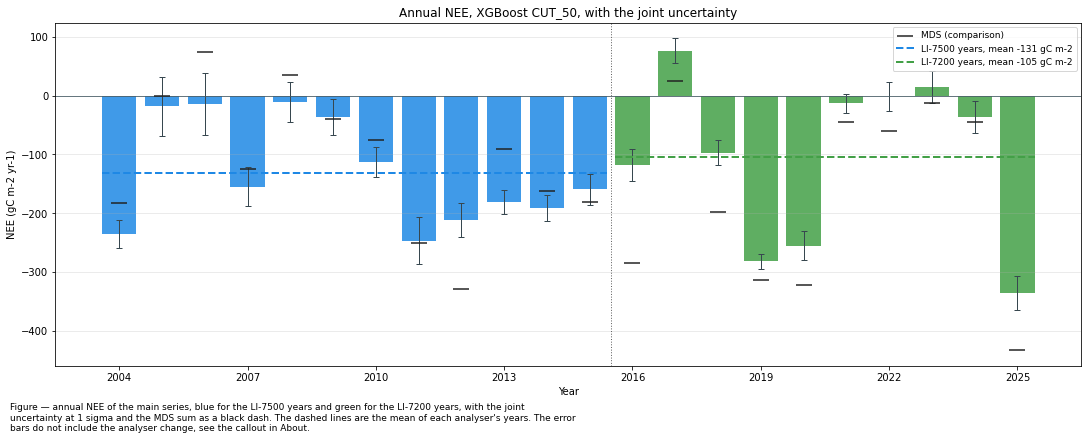

In [13]:
_colors = annual['analyser'].map({'LI-7500': '#1E88E5', 'LI-7200': '#43A047'})
fig, ax = plt.subplots(figsize=(15, 6), dpi=72, layout="constrained")
ax.bar(annual.index, annual[f"NEE ({units_sum})"], color=_colors, alpha=0.85,
       yerr=annual["joint unc."], capsize=3, error_kw=dict(lw=1, ecolor='#37474F'))
ax.scatter(annual.index, annual["MDS"], marker='_', s=250, color='#212121', zorder=5,
           label="MDS (comparison)")
for _name, _c in (('LI-7500', '#1E88E5'), ('LI-7200', '#43A047')):
    _x = annual.loc[annual['analyser'] == _name, f"NEE ({units_sum})"]
    ax.hlines(_x.mean(), _x.index.min() - 0.4, _x.index.max() + 0.4, color=_c, lw=2, ls='--',
              label=f"{_name} years, mean {_x.mean():.0f} {units_sum}")
ax.axhline(0, color='#455A64', lw=0.8)
ax.axvline(2015.5, color='#616161', lw=1, ls=':')
ax.set_xlabel("Year")
ax.set_ylabel(f"NEE ({units_sum} yr-1)")
ax.set_title("Annual NEE, XGBoost CUT_50, with the joint uncertainty")
ax.grid(alpha=0.3, axis='y')
ax.legend(fontsize=9)
year_axis(ax)
figcap(fig, "annual NEE of the main series, blue for the LI-7500 years and green for the LI-7200 years, "
            "with the joint uncertainty at 1 sigma and the MDS sum as a black dash. The dashed lines "
            "are the mean of each analyser's years. The error bars do not include the analyser "
            "change, see the callout in About.")
fig.show()

## 📋 Table: the LI-7500 years against the LI-7200 years

In [14]:
# The two analysers' years side by side. A difference here mixes the forest, the weather and the
# instrument; the parallel period and the responses further below separate them where possible.
_cols = [f"NEE ({units_sum})", "GPP (NT)", "RECO (NT)", "GPP (DT)", "RECO (DT)", "measured (%)"]
_g = annual.groupby('analyser')[_cols]
eras = pd.concat({'mean': _g.mean(), 'SD between years': _g.std(), 'years': _g.count()}, axis=1)
eras = eras.loc[['LI-7500', 'LI-7200']]
eras.loc['difference (LI-7200 minus LI-7500)', 'mean'] = (eras.loc['LI-7200', 'mean']
                                                          - eras.loc['LI-7500', 'mean']).to_numpy()
display(styled(eras, caption=f"means of the annual sums over the years of each analyser, "
                             f"{FIRST_YEAR}-2015 and 2016-{LAST_YEAR}, with the standard deviation "
                             f"between years. GPP and RECO (DT) of the LI-7500 years start in 2005",
               fmt="{:.0f}", cmap=None))

Table — means of the annual sums over the years of each analyser, 2004-2015 and 2016-2025, with the
standard deviation between years. GPP and RECO (DT) of the LI-7500 years start in 2005



</br>

# Partitioning

GPP and RECO are not measured; the partitioning models them from NEE. The nighttime method fits
respiration to measured nighttime NEE and temperature; the daytime method fits a light response to
daytime NEE. The two are independent estimates, and their difference is a measure of how far either
can be trusted.

## 📊 Plot: annual GPP and RECO from both methods

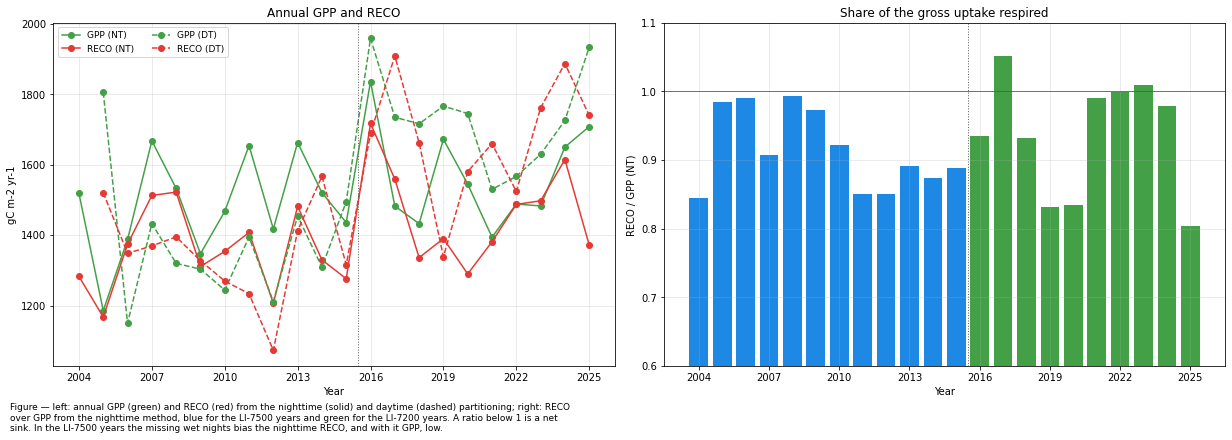

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(17, 6), dpi=72, layout="constrained")
for _method, _ls in (('NT', '-'), ('DT', '--')):
    axs[0].plot(annual.index, annual[f"GPP ({_method})"], color='#43A047', ls=_ls, marker='o',
                label=f"GPP ({_method})")
    axs[0].plot(annual.index, annual[f"RECO ({_method})"], color='#E53935', ls=_ls, marker='o',
                label=f"RECO ({_method})")
axs[0].set_ylabel(f"{units_sum} yr-1")
axs[0].set_title("Annual GPP and RECO")
_ratio = annual["RECO (NT)"] / annual["GPP (NT)"]
axs[1].bar(annual.index, _ratio, color=annual['analyser'].map({'LI-7500': '#1E88E5', 'LI-7200': '#43A047'}))
axs[1].axhline(1, color='#455A64', lw=0.8)
axs[1].set_ylim(0.6, 1.1)
axs[1].set_ylabel("RECO / GPP (NT)")
axs[1].set_title("Share of the gross uptake respired")
for _ax in axs:
    _ax.axvline(2015.5, color='#616161', lw=1, ls=':')
    _ax.grid(alpha=0.3)
    _ax.set_xlabel("Year")
    year_axis(_ax)
axs[0].legend(fontsize=9, ncol=2)
figcap(fig, "left: annual GPP (green) and RECO (red) from the nighttime (solid) and daytime (dashed) "
            "partitioning; right: RECO over GPP from the nighttime method, blue for the LI-7500 years "
            "and green for the LI-7200 years. A ratio below 1 is a net sink. In the LI-7500 years "
            "the missing wet nights bias the nighttime RECO, and with it GPP, low.")
fig.show()

</br>

# Seasonality

## Monthly sums per year

### 📋 Table: monthly sums per year

In [16]:
monthly_sum = per_year_month(series, to_gc)
monthly_by_number = per_year_month(series, to_gc, month_names=False)
display(styled(monthly_sum, caption=f"monthly NEE sums ({units_sum}), one row per year. Blue is uptake, "
                                    f"red is release; the colour scale runs over the whole table",
               fmt="{:.0f}", cmap='RdBu_r', axis=None, center=True))

Table — monthly NEE sums (gC m-2), one row per year. Blue is uptake, red is release; the colour
scale runs over the whole table



,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
YEAR,,,,,,,,,,,,
2004,-12,64,38,11,-63,-84,-81,-65,-30,20,29,-61
2005,89,31,69,21,-58,-95,-94,-74,-34,54,63,11
2006,61,36,16,35,-80,-93,-49,-87,-29,31,111,34
2007,65,63,29,14,-115,-110,-94,-77,-35,-2,68,40
2008,89,74,51,34,-75,-118,-111,-85,-56,39,90,58
2009,50,57,43,40,-78,-133,-110,-57,-51,51,97,54
2010,36,49,49,34,-66,-104,-106,-81,-53,23,57,49
2011,48,42,42,-2,-145,-155,-126,-82,-36,15,66,88
2012,64,48,63,8,-100,-137,-125,-99,-49,13,44,58


## Climatology per calendar month

### 📋 Table: climatology per calendar month

In [17]:
_by_month = monthly_by_number
climatology = pd.DataFrame({
    f"mean ({units_sum})": _by_month.mean(),
    "SD between years": _by_month.std(),
    "most uptake": _by_month.min(),
    "in": _by_month.idxmin(),
    "least uptake": _by_month.max(),
    "in ": _by_month.idxmax(),
    f"mean, LI-7500 years": _by_month.loc[:2015].mean(),
    f"mean, LI-7200 years": _by_month.loc[2016:].mean(),
})
climatology["LI-7200 minus LI-7500"] = climatology["mean, LI-7200 years"] - climatology["mean, LI-7500 years"]
climatology.index = [calendar.month_abbr[m] for m in climatology.index]
climatology.index.name = 'MONTH'
_fmt = {c: "{:.0f}" for c in climatology.columns}
_fmt["LI-7200 minus LI-7500"] = "{:+.0f}"
display(styled(climatology, caption=f"each calendar month across {FIRST_YEAR}-{LAST_YEAR}: its mean sum, "
                                    f"the spread between years, the years of most and least uptake, and "
                                    f"the mean over the years of each analyser. The last column shows in "
                                    f"which months the two analysers' years differ",
               fmt=_fmt, subset=["LI-7200 minus LI-7500"], cmap='RdBu_r', center=True))

Table — each calendar month across 2004-2025: its mean sum, the spread between years, the years of
most and least uptake, and the mean over the years of each analyser. The last column shows in which
months the two analysers' years differ



,mean (gC m-2),SD between years,most uptake,in,least uptake,in,"mean, LI-7500 years","mean, LI-7200 years",LI-7200 minus LI-7500
MONTH,,,,,,,,,
Jan,70,24,-12,2004,102,2016,60,82,+22
Feb,53,15,30,2015,79,2017,47,60,+12
Mar,38,16,8,2015,69,2005,38,37,-0
Apr,14,18,-23,2020,40,2009,20,6,-14
May,-96,32,-155,2025,-29,2021,-92,-101,-10
Jun,-131,24,-174,2025,-84,2004,-119,-145,-26
Jul,-115,27,-165,2019,-49,2006,-102,-130,-29
Aug,-81,22,-123,2025,-43,2022,-81,-81,+0
Sep,-52,17,-97,2019,-29,2006,-47,-59,-12


## Mean annual cycle

### 📊 Plot: mean annual cycle of daily NEE, per analyser

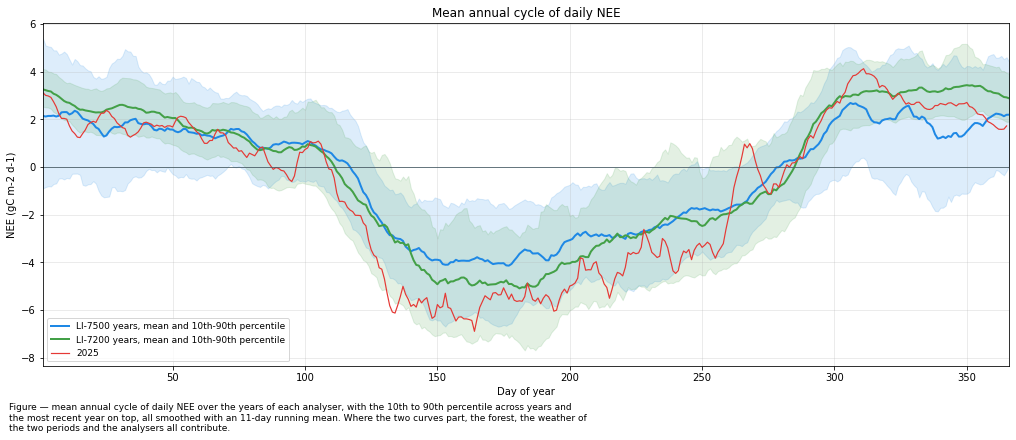

In [18]:
# Daily sums per day of year, smoothed with an 11-day running mean, for the years of each analyser.
fig, ax = plt.subplots(figsize=(14, 6), dpi=72, layout="constrained")
_sm = lambda s: s.rolling(11, center=True, min_periods=3).mean()
for _name, _sel, _c in (('LI-7500', daily.loc[:'2015'], '#1E88E5'), ('LI-7200', daily.loc['2016':], '#43A047')):
    _g = _sel['NEE'].groupby(_sel.index.dayofyear)
    ax.fill_between(_g.mean().index, _sm(_g.quantile(0.1)), _sm(_g.quantile(0.9)), color=_c, alpha=0.15)
    ax.plot(_g.mean().index, _sm(_g.mean()), color=_c, lw=2,
            label=f"{_name} years, mean and 10th-90th percentile")
_last = daily.loc[str(LAST_YEAR), 'NEE']
ax.plot(_last.index.dayofyear, _sm(_last), color='#E53935', lw=1.2, label=str(LAST_YEAR))
ax.axhline(0, color='#455A64', lw=0.8)
ax.set_xlim(1, 366)
ax.set_xlabel("Day of year")
ax.set_ylabel(f"NEE ({units_sum} d-1)")
ax.set_title("Mean annual cycle of daily NEE")
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc='lower left')
figcap(fig, "mean annual cycle of daily NEE over the years of each analyser, with the 10th to 90th "
            "percentile across years and the most recent year on top, all smoothed with an 11-day "
            "running mean. Where the two curves part, the forest, the weather of the two periods and "
            "the analysers all contribute.")
fig.show()

## Mean diurnal cycle per month

### 📊 Plot: mean diurnal cycle per month, per analyser

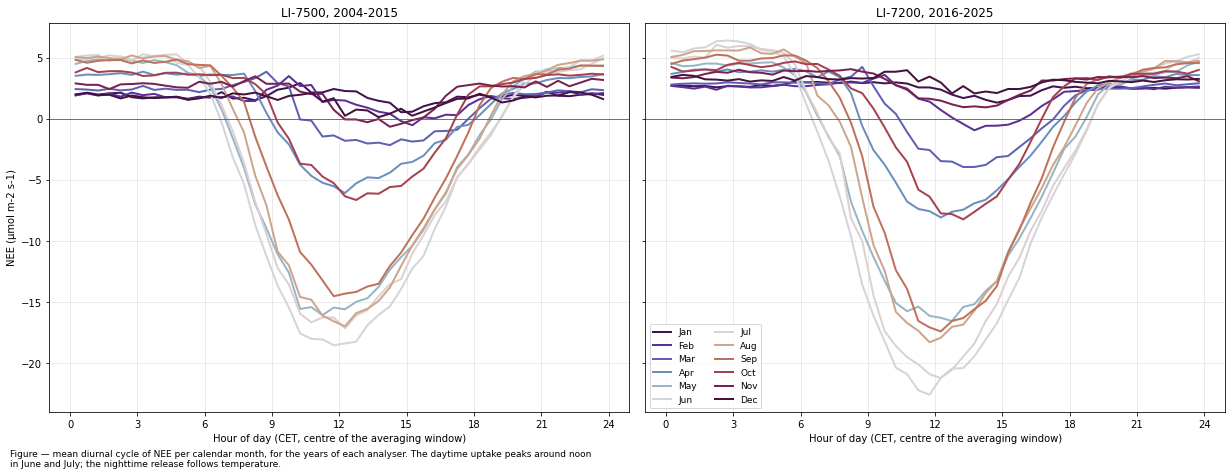

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(17, 6.5), dpi=72, sharey=True, layout="constrained")
_colors = plt.get_cmap('twilight_shifted')(np.linspace(0.05, 0.95, 12))
for _ax, (_name, _s) in zip(axs, (('LI-7500, 2004-2015', series.loc[:'2015']),
                                  (f'LI-7200, 2016-{LAST_YEAR}', series.loc['2016':]))):
    _diurnal = _s.groupby([_s.index.month, _s.index.hour + _s.index.minute / 60]).mean().unstack(0)
    for _i, _month in enumerate(_diurnal.columns):
        _ax.plot(_diurnal.index, _diurnal[_month], color=_colors[_i], lw=2, label=calendar.month_abbr[_month])
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.set_xticks(range(0, 25, 3))
    _ax.set_xlabel("Hour of day (CET, centre of the averaging window)")
    _ax.set_title(_name)
    _ax.grid(alpha=0.3)
axs[0].set_ylabel(xlabel)
axs[1].legend(ncol=2, fontsize=9)
figcap(fig, "mean diurnal cycle of NEE per calendar month, for the years of each analyser. The daytime "
            "uptake peaks around noon in June and July; the nighttime release follows temperature.")
fig.show()

## Month by hour

### 📊 Plot: month by hour, and the difference between the analysers' years

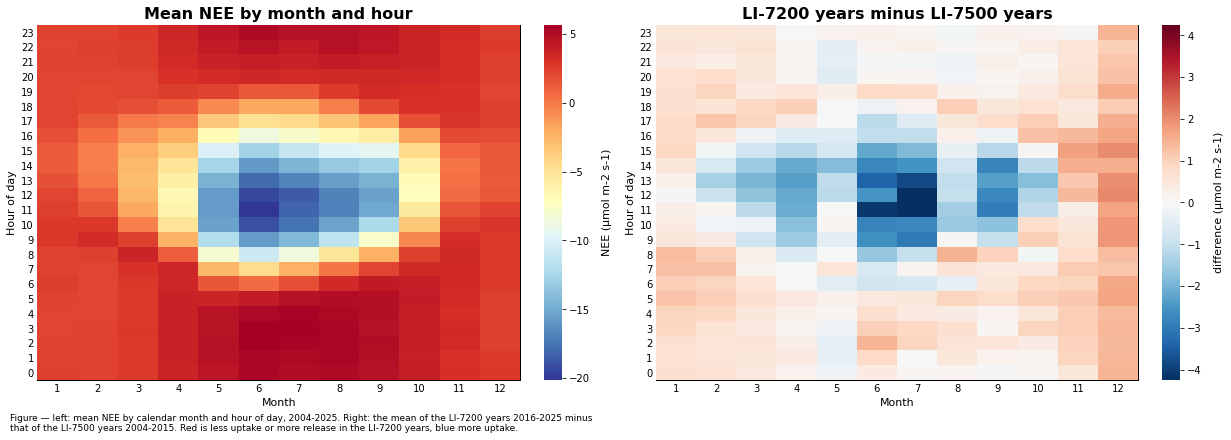

In [20]:
def _by_month_hour(s):
    """Mean of `s` per calendar month and hour, in the long form HeatmapXYZ expects."""
    frame = pd.DataFrame({'MONTH': s.index.month, 'HOUR': s.index.hour, 'z': s.to_numpy()})
    return frame.groupby(['MONTH', 'HOUR'], as_index=False)['z'].mean()


_all = _by_month_hour(series)
_diff = _by_month_hour(series.loc['2016':])
_diff['z'] = _diff['z'].to_numpy() - _by_month_hour(series.loc[:'2015'])['z'].to_numpy()
_absmax = _diff['z'].abs().max()
_style = dict(axlabel_fontsize=11, ticks_fontsize=10)
fig, axs = plt.subplots(ncols=2, figsize=(17, 6), dpi=72, layout="constrained")
dv.plotting.HeatmapXYZ(x=_all['MONTH'], y=_all['HOUR'], z=_all['z']).plot(
    ax=axs[0], xlabel="Month", ylabel="Hour of day", zlabel=xlabel, cb_labelsize=10,
    format_style=dv.plotting.FormatStyle(title=f"Mean {var} by month and hour", **_style))
dv.plotting.HeatmapXYZ(x=_diff['MONTH'], y=_diff['HOUR'], z=_diff['z']).plot(
    ax=axs[1], cmap='RdBu_r', vmin=-_absmax, vmax=_absmax, xlabel="Month", ylabel="Hour of day",
    zlabel=f"difference ({units})", cb_labelsize=10,
    format_style=dv.plotting.FormatStyle(title="LI-7200 years minus LI-7500 years", **_style))
figcap(fig, f"left: mean NEE by calendar month and hour of day, {FIRST_YEAR}-{LAST_YEAR}. Right: the mean "
            f"of the LI-7200 years 2016-{LAST_YEAR} minus that of the LI-7500 years 2004-2015. Red is "
            f"less uptake or more release in the LI-7200 years, blue more uptake.")

</br>

# Carbon uptake period

The carbon uptake period is the part of the year in which the forest is a net sink. Here it is the
longest run of days with a negative running mean of daily NEE (window in Settings), which skips
single sunny days in winter and single cloudy days in summer.

## 📋 Table: carbon uptake period per year

In [21]:
_smooth = daily['NEE'].rolling(CUP_SMOOTHING_DAYS, center=True, min_periods=CUP_SMOOTHING_DAYS // 2).mean()
_rows = {}
for _y in range(FIRST_YEAR, LAST_YEAR + 1):
    _s = _smooth.loc[str(_y)]
    _len, _start = longest_spell(_s < 0)
    _end = _start + pd.Timedelta(days=_len - 1) if _len else pd.NaT
    _rows[_y] = {'analyser': era(_y), 'start': _start, 'end': _end, 'length (d)': _len,
                 'start (day of year)': _start.dayofyear if _len else np.nan,
                 'end (day of year)': _end.dayofyear if _len else np.nan,
                 f"NEE in the period ({units_sum})": daily.loc[_start:_end, 'NEE'].sum() if _len else np.nan,
                 f"NEE outside ({units_sum})": (daily.loc[str(_y), 'NEE'].sum()
                                                - (daily.loc[_start:_end, 'NEE'].sum() if _len else 0))}
cup = pd.DataFrame.from_dict(_rows, orient='index')
cup.index.name = 'YEAR'
_show = cup.copy()
_show['start'] = _show['start'].dt.strftime('%d %b')
_show['end'] = _show['end'].dt.strftime('%d %b')
display(styled(_show, caption=f"carbon uptake period per year: the longest run of days with a negative "
                              f"{CUP_SMOOTHING_DAYS}-day running mean of daily NEE, with the NEE summed "
                              f"inside and outside it",
               fmt={'length (d)': "{:.0f}", 'start (day of year)': "{:.0f}", 'end (day of year)': "{:.0f}",
                    f"NEE in the period ({units_sum})": "{:.0f}", f"NEE outside ({units_sum})": "{:.0f}"},
               subset=['length (d)'], cmap='Greens'))

Table — carbon uptake period per year: the longest run of days with a negative 15-day running mean
of daily NEE, with the NEE summed inside and outside it



,analyser,start,end,length (d),start (day of year),end (day of year),NEE in the period (gC m-2),NEE outside (gC m-2)
YEAR,,,,,,,,
2004,LI-7500,29 Apr,01 Oct,156,120,275,-323,88
2005,LI-7500,04 May,05 Oct,155,124,278,-366,347
2006,LI-7500,02 May,03 Oct,155,122,276,-339,325
2007,LI-7500,22 Apr,20 Oct,182,112,293,-446,291
2008,LI-7500,05 May,05 Oct,154,126,279,-445,434
2009,LI-7500,24 Apr,02 Oct,162,114,275,-428,392
2010,LI-7500,02 May,09 Oct,161,122,282,-410,296
2011,LI-7500,17 Apr,02 Oct,169,107,275,-570,324
2012,LI-7500,29 Apr,04 Oct,159,120,278,-509,297


## 📊 Plot: start, end and length of the carbon uptake period

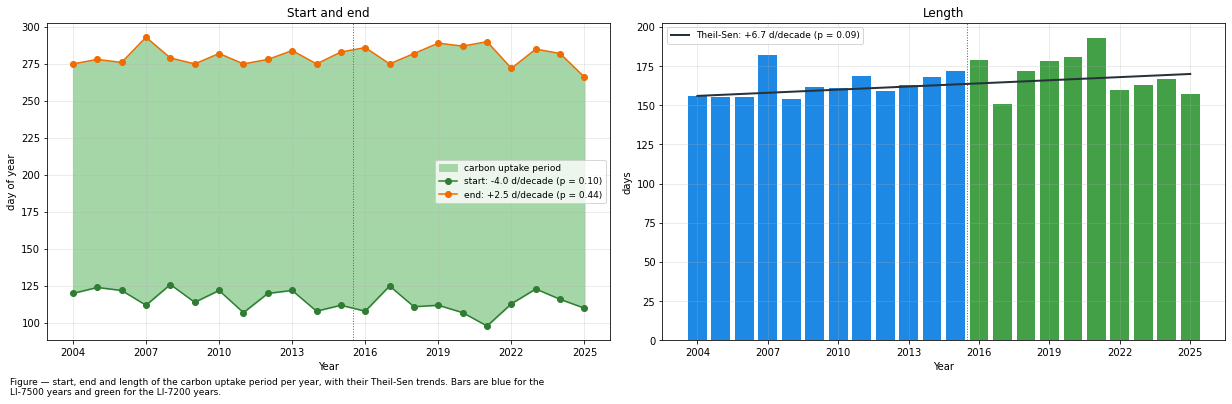

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(17, 5.5), dpi=72, layout="constrained")
axs[0].fill_between(cup.index, cup['start (day of year)'], cup['end (day of year)'], color='#A5D6A7',
                    label="carbon uptake period")
for _c, _col in (('start (day of year)', '#2E7D32'), ('end (day of year)', '#EF6C00')):
    _fit = trend(cup[_c].dropna())
    axs[0].plot(cup.index, cup[_c], marker='o', color=_col, lw=1.5,
                label=f"{_c.split(' ')[0]}: {_fit['slope']:+.1f} d/decade (p = {_fit['pvalue']:.2f})")
axs[0].set_ylabel("day of year")
axs[0].set_title("Start and end")
_fit = trend(cup['length (d)'])
axs[1].bar(cup.index, cup['length (d)'], color=cup['analyser'].map({'LI-7500': '#1E88E5', 'LI-7200': '#43A047'}))
axs[1].plot(_fit['fit'].index, _fit['fit'], color='#263238', lw=2,
            label=f"Theil-Sen: {_fit['slope']:+.1f} d/decade (p = {_fit['pvalue']:.2f})")
axs[1].set_ylabel("days")
axs[1].set_title("Length")
for _ax in axs:
    _ax.axvline(2015.5, color='#616161', lw=1, ls=':')
    _ax.set_xlabel("Year")
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9)
    year_axis(_ax)
figcap(fig, "start, end and length of the carbon uptake period per year, with their Theil-Sen trends. "
            "Bars are blue for the LI-7500 years and green for the LI-7200 years.")
fig.show()

</br>

# Extremes

From the gap-filled series, with the measured share of each day listed beside it.

## The days of most uptake and most release

### 📋 Table: the days of most uptake

In [23]:
def _ranked_days(_label, _ranked):
    _table = pd.DataFrame({"date": [f"{_d:%d %b %Y}" for _d in _ranked.index],
                           f"NEE ({units_sum} d-1)": _ranked.to_numpy(),
                           f"GPP NT ({units_sum} d-1)": daily.loc[_ranked.index, 'GPP_NT'].to_numpy(),
                           f"RECO NT ({units_sum} d-1)": daily.loc[_ranked.index, 'RECO_NT'].to_numpy(),
                           "measured (%)": daily.loc[_ranked.index, 'measured (%)'].to_numpy(),
                           "analyser": [era(_d.year) for _d in _ranked.index]},
                          index=range(1, N_EXTREMES + 1))
    _table.index.name = "rank"
    display(styled(_table, caption=f"the {N_EXTREMES} days of {_label} in {FIRST_YEAR}-{LAST_YEAR}, with "
                                   f"the partitioned fluxes and the measured share of the day",
                   fmt={f"NEE ({units_sum} d-1)": "{:.2f}", f"GPP NT ({units_sum} d-1)": "{:.2f}",
                        f"RECO NT ({units_sum} d-1)": "{:.2f}", "measured (%)": "{:.0f}"},
                   subset=["measured (%)"], cmap='Blues'))


_ranked_days('most uptake', daily['NEE'].nsmallest(N_EXTREMES))

Table — the 10 days of most uptake in 2004-2025, with the partitioned fluxes and the measured share
of the day



,date,NEE (gC m-2 d-1),GPP NT (gC m-2 d-1),RECO NT (gC m-2 d-1),measured (%),analyser
rank,,,,,,
1,08 Dec 2004,-19.69,19.69,0.00,71,LI-7500
2,07 Dec 2004,-13.79,13.79,0.00,52,LI-7500
3,09 Dec 2004,-13.01,13.01,0.00,65,LI-7500
4,06 Jul 2013,-10.57,11.62,1.05,62,LI-7500
5,09 Jun 2025,-10.28,16.19,5.91,40,LI-7200
6,05 Dec 2004,-10.22,10.22,0.00,44,LI-7500
7,24 May 2020,-9.99,14.03,4.04,54,LI-7200
8,24 May 2025,-9.89,12.34,2.45,56,LI-7200
9,29 May 2025,-9.81,13.09,3.28,58,LI-7200


### 📋 Table: the days of most release

In [24]:
_ranked_days('most release', daily['NEE'].nlargest(N_EXTREMES))

Table — the 10 days of most release in 2004-2025, with the partitioned fluxes and the measured share
of the day



,date,NEE (gC m-2 d-1),GPP NT (gC m-2 d-1),RECO NT (gC m-2 d-1),measured (%),analyser
rank,,,,,,
1,31 Jan 2006,12.76,-3.92,8.84,60,LI-7500
2,13 Dec 2022,12.60,-8.93,3.67,52,LI-7200
3,21 Dec 2014,11.03,-5.32,5.70,88,LI-7500
4,04 Dec 2013,10.27,-5.43,4.84,69,LI-7500
5,29 Nov 2013,9.85,-6.92,2.93,46,LI-7500
6,31 Oct 2005,9.75,-5.51,4.24,25,LI-7500
7,17 Dec 2022,9.54,-6.62,2.92,71,LI-7200
8,19 Nov 2011,9.46,-5.83,3.63,19,LI-7500
9,24 Nov 2014,9.43,-6.26,3.18,38,LI-7500


## 📋 Table: strongest half-hourly uptake per year

In [25]:
# Measured half-hours only: a half-hourly extreme of the gap-filled series is a model value.
_idx = series_measured.groupby(series_measured.index.year).idxmin()
_peaks = pd.DataFrame({'analyser': [era(y) for y in _idx.index],
                       f"strongest uptake ({units})": series_measured.loc[_idx.to_numpy()].to_numpy(),
                       'averaging window': [window(t) for t in _idx.to_numpy()],
                       f"95th percentile of uptake ({units})": -(-series_measured).groupby(
                           series_measured.index.year).quantile(0.95)}, index=_idx.index)
_peaks.index.name = 'YEAR'
display(styled(_peaks, caption=f"the strongest measured half-hourly uptake of each year and the 95th "
                               f"percentile of measured uptake, which is less sensitive to a single "
                               f"half-hour",
               fmt={f"strongest uptake ({units})": "{:.1f}", f"95th percentile of uptake ({units})": "{:.1f}"},
               subset=[f"95th percentile of uptake ({units})"], cmap='Blues_r'))

Table — the strongest measured half-hourly uptake of each year and the 95th percentile of measured
uptake, which is less sensitive to a single half-hour



,analyser,strongest uptake (µmol m-2 s-1),averaging window,95th percentile of uptake (µmol m-2 s-1)
YEAR,,,,
2004,LI-7500,-47.8,"08 Dec 2004, 10:00 to 10:30",-18.9
2005,LI-7500,-49.9,"27 Apr 2005, 08:00 to 08:30",-19.0
2006,LI-7500,-49.2,"07 Aug 2006, 12:00 to 12:30",-18.2
2007,LI-7500,-49.0,"19 Aug 2007, 11:00 to 11:30",-21.7
2008,LI-7500,-49.9,"11 Jun 2008, 10:30 to 11:00",-22.3
2009,LI-7500,-49.9,"11 Jun 2009, 08:00 to 08:30",-22.8
2010,LI-7500,-49.6,"07 May 2010, 10:00 to 10:30",-21.8
2011,LI-7500,-49.3,"17 Jun 2011, 10:30 to 11:00",-24.0
2012,LI-7500,-48.8,"19 Jun 2012, 09:30 to 10:00",-23.7


</br>

# Responses to light and temperature

The response of NEE to its two main drivers, from measured records only, for the years of each
analyser. If the change of analyser had shifted the flux, the curves of the two periods would part
under the same conditions. Weather and the forest itself change the curves as well, so a difference
is a hint, not a proof.

## 📊 Plot: light response and nighttime temperature response

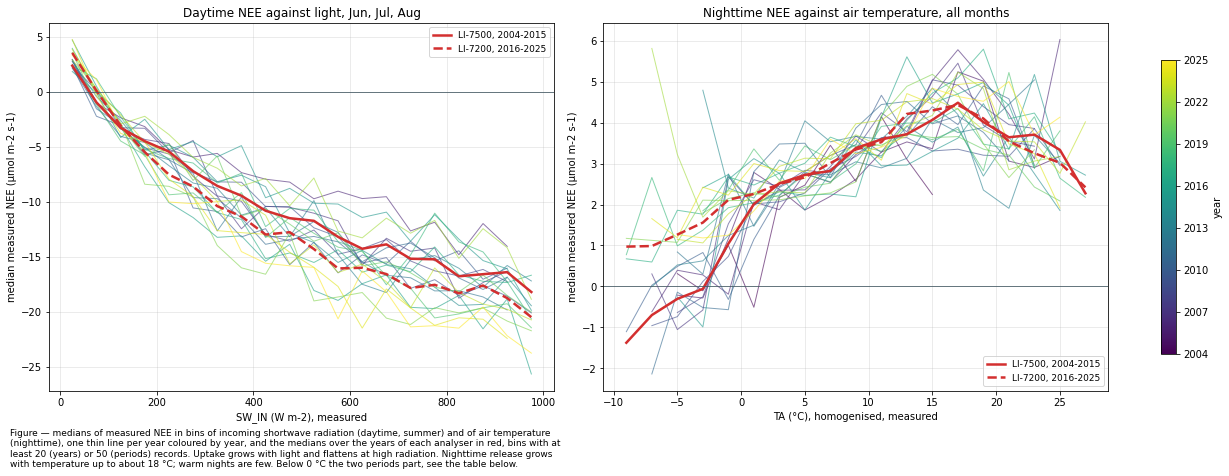

In [26]:
_bins_light = np.arange(0, 1001, 50)
_bins_ta = np.arange(-10, 31, 2)
fig, axs = plt.subplots(1, 2, figsize=(17, 6.5), dpi=72, layout="constrained")
_day = df[[varname_measured, SW_IN]].where(df[DAYTIME].eq(1)).dropna()
_day = _day[_day.index.month.isin(LIGHT_MONTHS)]
_night = df[[varname_measured, TA]].where(df[NIGHTTIME].eq(1)).dropna()
_cmap = plt.get_cmap('viridis')


def _binned(d, x, bins, min_count):
    """Median measured NEE per bin of `x`, for bins holding at least `min_count` records."""
    _g = d.groupby(pd.cut(d[x], bins), observed=True)[varname_measured]
    _med = _g.median()[_g.count() >= min_count]
    return [i.mid for i in _med.index], _med.to_numpy()


_years = range(FIRST_YEAR, LAST_YEAR + 1)
for _y in _years:
    _c = _cmap((_y - FIRST_YEAR) / (LAST_YEAR - FIRST_YEAR))
    for _ax, _d, _x, _bins in ((axs[0], _day, SW_IN, _bins_light), (axs[1], _night, TA, _bins_ta)):
        _sel = _d[_d.index.year == _y]
        if len(_sel) < 200:
            continue
        _ax.plot(*_binned(_sel, _x, _bins, 20), color=_c, lw=1, alpha=0.6)
for _name, _sel_years, _ls in (('LI-7500, 2004-2015', lambda i: i.year < 2016, '-'),
                               (f'LI-7200, 2016-{LAST_YEAR}', lambda i: i.year >= 2016, '--')):
    for _ax, _d, _x, _bins in ((axs[0], _day, SW_IN, _bins_light), (axs[1], _night, TA, _bins_ta)):
        _sel = _d[_sel_years(_d.index)]
        _ax.plot(*_binned(_sel, _x, _bins, 50), color='#D32F2F', lw=2.5, ls=_ls, label=_name)
axs[0].set_xlabel("SW_IN (W m-2), measured")
axs[0].set_title(f"Daytime NEE against light, {', '.join(calendar.month_abbr[m] for m in LIGHT_MONTHS)}")
axs[1].set_xlabel("TA (°C), homogenised, measured")
axs[1].set_title("Nighttime NEE against air temperature, all months")
for _ax in axs:
    _ax.set_ylabel(f"median measured NEE ({units})")
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9)
_sm = plt.cm.ScalarMappable(cmap=_cmap, norm=Normalize(FIRST_YEAR, LAST_YEAR))
_cb = fig.colorbar(_sm, ax=axs, label="year", shrink=0.8)
_cb.locator = plt.MaxNLocator(integer=True)
_cb.update_ticks()
figcap(fig, "medians of measured NEE in bins of incoming shortwave radiation (daytime, summer) and of "
            "air temperature (nighttime), one thin line per year coloured by year, and the medians "
            "over the years of each analyser in red, bins with at least 20 (years) or 50 (periods) "
            "records. Uptake grows with light and flattens at high radiation. Nighttime release "
            "grows with temperature up to about 18 °C; warm nights are few. Below 0 °C the two "
            "periods part, see the table below.")
fig.show()

## 📋 Table: responses per analyser

In [27]:
def _response(d, x, lo, hi):
    """Median measured NEE of the records with `x` between `lo` and `hi`."""
    return d.loc[(d[x] >= lo) & (d[x] < hi), varname_measured].median()


_rows = {}
for _name, _sel in (('LI-7500, 2004-2015', lambda i: i.year < 2016),
                    ('LI-7200, 2016-2025', lambda i: i.year >= 2016)):
    _d, _n = _day[_sel(_day.index)], _night[_sel(_night.index)]
    _rows[_name] = {f"daytime NEE at SW_IN 700-900 W m-2 ({units})": _response(_d, SW_IN, 700, 900),
                    f"daytime NEE at SW_IN 100-200 W m-2 ({units})": _response(_d, SW_IN, 100, 200),
                    f"nighttime NEE at TA 14-16 °C ({units})": _response(_n, TA, 14, 16),
                    f"nighttime NEE at TA 4-6 °C ({units})": _response(_n, TA, 4, 6),
                    f"nighttime NEE at TA below 0 °C ({units})": _response(_n, TA, -30, 0),
                    "measured daytime records": len(_d), "measured nighttime records": len(_n)}
responses = pd.DataFrame.from_dict(_rows, orient='index')
responses.loc['difference'] = responses.iloc[1] - responses.iloc[0]
display(styled(responses, caption="median measured NEE under fixed conditions, for the years of each "
                                  "analyser: bright and dim summer daylight, and warm and cool nights",
               fmt={c: ("{:.0f}" if 'records' in c else "{:+.2f}") for c in responses.columns}, cmap=None))

# Respiration does not stop below 0 °C, so nighttime NEE should stay positive. A negative median is
# an apparent uptake in the dark, which points at the measurement rather than at the forest.
_cold = responses[f"nighttime NEE at TA below 0 °C ({units})"]
for _name in responses.index[:2]:
    print(f"{_name}: median nighttime NEE below 0 °C = {_cold[_name]:+.2f} {units}"
          + ("  <- apparent uptake at night" if _cold[_name] < 0 else ""))

Table — median measured NEE under fixed conditions, for the years of each analyser: bright and dim
summer daylight, and warm and cool nights



,daytime NEE at SW_IN 700-900 W m-2 (µmol m-2 s-1),daytime NEE at SW_IN 100-200 W m-2 (µmol m-2 s-1),nighttime NEE at TA 14-16 °C (µmol m-2 s-1),nighttime NEE at TA 4-6 °C (µmol m-2 s-1),nighttime NEE at TA below 0 °C (µmol m-2 s-1),measured daytime records,measured nighttime records
"LI-7500, 2004-2015",-15.97,-3.68,+4.07,+2.72,+0.08,13585,28456
"LI-7200, 2016-2025",-17.81,-4.23,+4.30,+2.67,+1.67,17380,32365
difference,-1.84,-0.55,+0.23,-0.06,+1.59,3795,3909


LI-7500, 2004-2015: median nighttime NEE below 0 °C = +0.08 µmol m-2 s-1
LI-7200, 2016-2025: median nighttime NEE below 0 °C = +1.67 µmol m-2 s-1


</br>

# The two analysers in parallel

From 11 January 2016 to 12 December 2017 both analysers measured. The merged record uses the
LI-7200; this section reads both per-analyser records over these two years. On the half-hours both
measured, the comparison is direct. Over all half-hours, it includes the gap-filling, and there the
LI-7500 misses many wet half-hours that the LI-7200 measures.

In [28]:
_cols = [varname_measured, varname]
par = pd.concat({'IRGA75': load_parquet(filepath=Path(DATADIR) / FILE_IRGA75)[_cols],
                 'IRGA72': load_parquet(filepath=Path(DATADIR) / FILE_IRGA72)[_cols]}, axis=1)
par = par.loc[PARALLEL[0]:PARALLEL[1] + ' 23:45']
both = par.xs(varname_measured, axis=1, level=1).dropna()
print(f"Parallel period: {par.index[0]} -> {par.index[-1]} ({len(par):,} half-hours)")
print(f"Both measured:   {len(both):,} half-hours ({100 * len(both) / len(par):.1f} %)")
for _a in ('IRGA75', 'IRGA72'):
    print(f"{_a} measured:     {par[(_a, varname_measured)].notna().mean() * 100:.1f} %")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA75\99_FPPC_IRGA75_MERGED_2004-2017.parquet (0.174 seconds).

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA72\99_FPPC_IRGA72_MERGED_2016-2026.09.parquet (0.144 seconds).

Parallel period: 2016-01-11 00:15:00 -> 2017-12-12 23:45:00 (33,696 half-hours)
Both measured:   10,280 half-hours (30.5 %)
IRGA75 measured:     40.1 %
IRGA72 measured:     43.3 %


## 📋 Table: sums of both analysers in the parallel period

In [29]:
_rows = {}
for _label, _s75, _s72 in (
        ("half-hours both measured", both['IRGA75'], both['IRGA72']),
        ("all half-hours, gap-filled", par[('IRGA75', varname)], par[('IRGA72', varname)])):
    for _part, _mask in (("all", None), ("day", True), ("night", False)):
        _m = slice(None) if _mask is None else (df_full.loc[_s75.index, DAYTIME].eq(1) == _mask).to_numpy()
        _a, _b = to_gc(_s75[_m]), to_gc(_s72[_m])
        _rows[(_label, _part)] = {f"LI-7500 ({units_sum})": _a, f"LI-7200 ({units_sum})": _b,
                                  f"LI-7500 minus LI-7200 ({units_sum})": _a - _b}
parallel = pd.DataFrame.from_dict(_rows, orient='index')
parallel.index.names = ['records', 'part of day']
display(styled(parallel, caption=f"NEE summed over {PARALLEL[0]} to {PARALLEL[1]} for both analysers: on "
                                 f"the half-hours both measured, and over all half-hours of each "
                                 f"gap-filled record. A negative difference is more uptake by the LI-7500",
               fmt="{:.0f}", subset=[f"LI-7500 minus LI-7200 ({units_sum})"], cmap='RdBu_r', center=True))

Table — NEE summed over 2016-01-11 to 2017-12-12 for both analysers: on the half-hours both
measured, and over all half-hours of each gap-filled record. A negative difference is more uptake by
the LI-7500



## 📊 Plot: cumulative NEE of both analysers in the parallel period

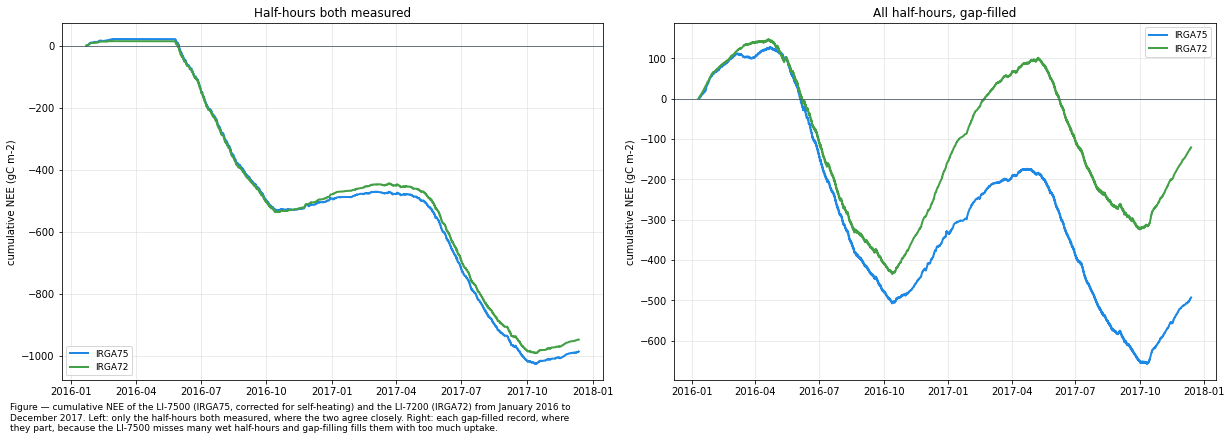

In [30]:
fig, axs = plt.subplots(1, 2, figsize=(17, 6), dpi=72, layout="constrained")
for _a, _c in (('IRGA75', '#1E88E5'), ('IRGA72', '#43A047')):
    axs[0].plot(both.index, both[_a].cumsum() * UMOL_TO_GC, color=_c, lw=2, label=_a)
    axs[1].plot(par.index, par[(_a, varname)].cumsum() * UMOL_TO_GC, color=_c, lw=2, label=_a)
axs[0].set_title("Half-hours both measured")
axs[1].set_title("All half-hours, gap-filled")
for _ax in axs:
    _ax.set_ylabel(f"cumulative NEE ({units_sum})")
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9)
figcap(fig, "cumulative NEE of the LI-7500 (IRGA75, corrected for self-heating) and the LI-7200 (IRGA72) "
            "from January 2016 to December 2017. Left: only the half-hours both measured, where the "
            "two agree closely. Right: each gap-filled record, where they part, because the LI-7500 "
            "misses many wet half-hours and gap-filling fills them with too much uptake.")
fig.show()

## 📊 Plot: the two analysers half-hour by half-hour

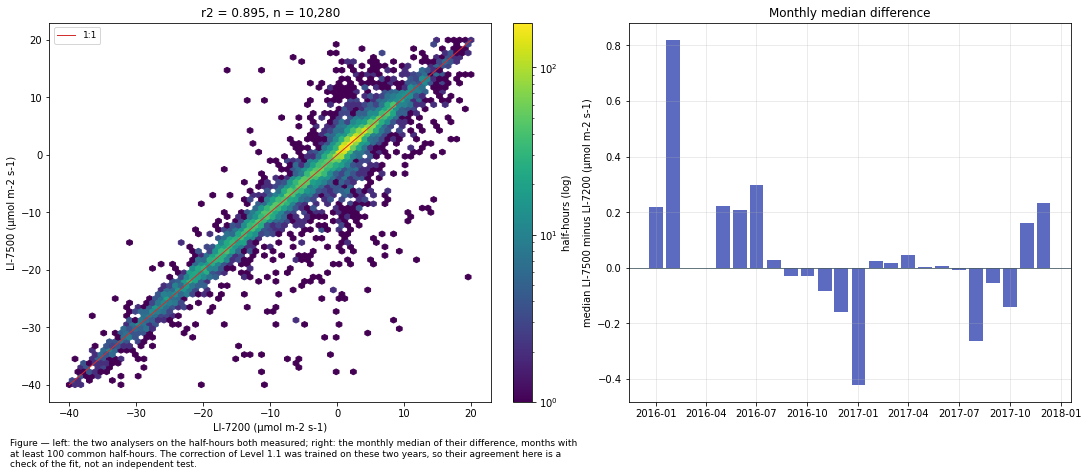

In [31]:
fig, axs = plt.subplots(1, 2, figsize=(15, 6.5), dpi=72, layout="constrained")
_hb = axs[0].hexbin(both['IRGA72'], both['IRGA75'], gridsize=70, mincnt=1, bins='log', cmap='viridis',
                    extent=(-40, 20, -40, 20))
axs[0].plot([-40, 20], [-40, 20], color='#D32F2F', lw=1, label='1:1')
axs[0].set_xlabel(f"LI-7200 ({units})")
axs[0].set_ylabel(f"LI-7500 ({units})")
axs[0].set_title(f"r2 = {both['IRGA72'].corr(both['IRGA75']) ** 2:.3f}, n = {len(both):,}")
axs[0].legend(fontsize=9)
fig.colorbar(_hb, ax=axs[0], label="half-hours (log)")
_diff = (both['IRGA75'] - both['IRGA72'])
_m = _diff.groupby(_diff.index.to_period('M')).agg(['median', 'count'])
_m = _m[_m['count'] >= 100]
axs[1].bar(_m.index.to_timestamp(), _m['median'], width=25, color='#5C6BC0')
axs[1].axhline(0, color='#455A64', lw=0.8)
axs[1].set_ylabel(f"median LI-7500 minus LI-7200 ({units})")
axs[1].set_title("Monthly median difference")
axs[1].grid(alpha=0.3)
figcap(fig, "left: the two analysers on the half-hours both measured; right: the monthly median of "
            "their difference, months with at least 100 common half-hours. The correction of Level 1.1 "
            "was trained on these two years, so their agreement here is a check of the fit, not an "
            "independent test.")
fig.show()

</br>

# Heatmap plots

## Half-hourly

### 📊 Plot: heatmap of the half-hourly values

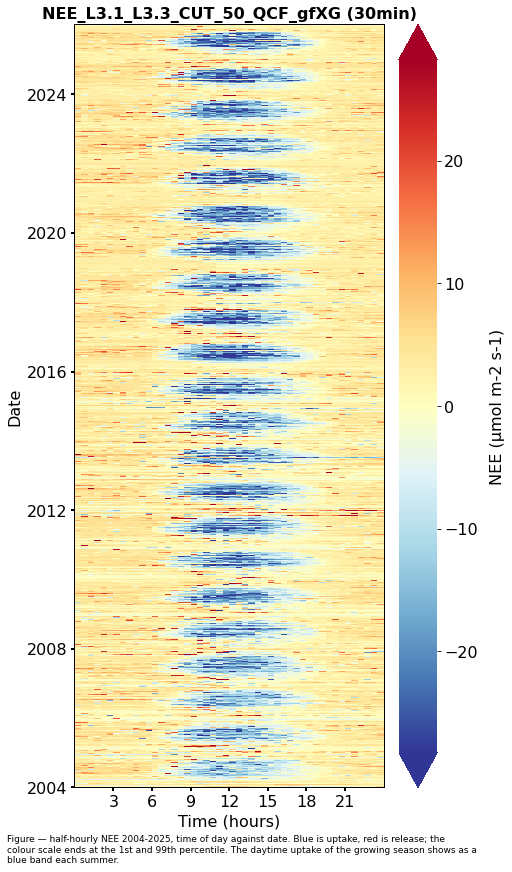

In [32]:
_lo, _hi = series.quantile([0.01, 0.99])
_lim = max(abs(_lo), abs(_hi))
fig, ax = plt.subplots(figsize=(7, 12), dpi=72, layout="constrained")
dv.plotting.HeatmapDateTime(series=series).plot(ax=ax, cmap='RdYlBu_r', vmin=-_lim, vmax=_lim,
                                                cb_extend='both', zlabel=xlabel)
figcap(fig, f"half-hourly NEE {FIRST_YEAR}-{LAST_YEAR}, time of day against date. Blue is uptake, red is "
            f"release; the colour scale ends at the 1st and 99th percentile. The daytime uptake of "
            f"the growing season shows as a blue band each summer.")

## Monthly

### 📊 Plot: monthly sums and their ranks

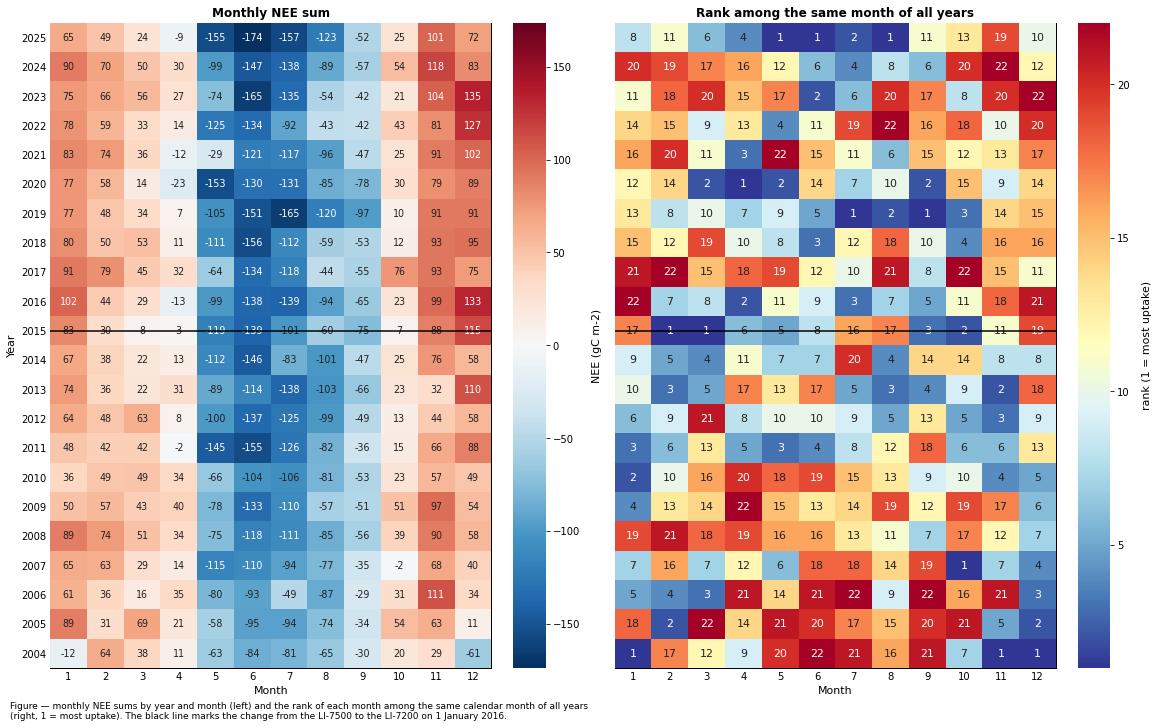

In [33]:
fig, axs = plt.subplots(ncols=2, figsize=(16, 10), dpi=72, sharey=True, layout="constrained")
_style = dv.plotting.FormatStyle(axlabel_fontsize=11, ticks_fontsize=10)
_long = monthly_by_number.stack().rename('z').reset_index()
_long.columns = ['YEAR', 'MONTH', 'z']
_absmax = _long['z'].abs().max()
dv.plotting.HeatmapXYZ(x=_long['MONTH'], y=_long['YEAR'], z=_long['z']).plot(
    ax=axs[0], cmap='RdBu_r', vmin=-_absmax, vmax=_absmax, xlabel="Month", ylabel="Year",
    zlabel=f"NEE ({units_sum})", show_values=True, cb_labelsize=10, format_style=_style)
# Rank 1 is the month of most uptake among the same calendar month of all years.
_ranks = monthly_by_number.rank(axis=0).stack().rename('z').reset_index()
_ranks.columns = ['YEAR', 'MONTH', 'z']
dv.plotting.HeatmapXYZ(x=_ranks['MONTH'], y=_ranks['YEAR'], z=_ranks['z']).plot(
    ax=axs[1], cmap='RdYlBu_r', xlabel="Month", ylabel="", zlabel="rank (1 = most uptake)",
    show_values=True, cb_labelsize=10, format_style=_style)
for _ax, _title in zip(axs, ["Monthly NEE sum", "Rank among the same month of all years"]):
    _ax.set_title(_title, fontsize=12, fontweight='bold', color='black')
    _ax.axhline(2015.5, color='black', lw=1.5, zorder=200)
figcap(fig, f"monthly NEE sums by year and month (left) and the rank of each month among the same "
            f"calendar month of all years (right, 1 = most uptake). The black line marks the change "
            f"from the LI-7500 to the LI-7200 on 1 January 2016.")

## Anomaly by year and month

### 📊 Plot: anomaly by year and month

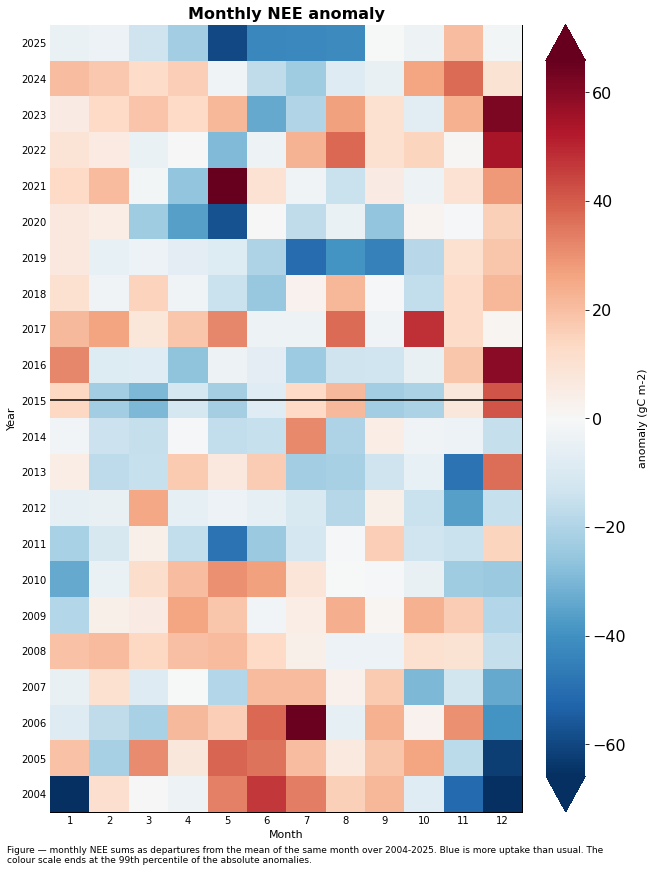

In [34]:
_anom = monthly_by_number - monthly_by_number.loc[REFERENCE_START_YEAR:REFERENCE_END_YEAR].mean()
_long = _anom.stack().rename('z').reset_index()
_long.columns = ['YEAR', 'MONTH', 'z']
_absmax = _long['z'].abs().quantile(0.99)
fig, ax = plt.subplots(figsize=(9, 12), dpi=72, layout="constrained")
dv.plotting.HeatmapXYZ(x=_long['MONTH'], y=_long['YEAR'], z=_long['z']).plot(
    ax=ax, cmap='RdBu_r', vmin=-_absmax, vmax=_absmax, cb_extend='both', xlabel="Month", ylabel="Year",
    zlabel=f"anomaly ({units_sum})",
    format_style=dv.plotting.FormatStyle(title=f"Monthly {var} anomaly", axlabel_fontsize=11, ticks_fontsize=10))
ax.axhline(2015.5, color='black', lw=1.5, zorder=200)
figcap(fig, f"monthly NEE sums as departures from the mean of the same month over "
            f"{REFERENCE_START_YEAR}-{REFERENCE_END_YEAR}. Blue is more uptake than usual. The colour "
            f"scale ends at the 99th percentile of the absolute anomalies.")

</br>

# Anomalies and trends

## Per year

### 📊 Plot: yearly anomalies

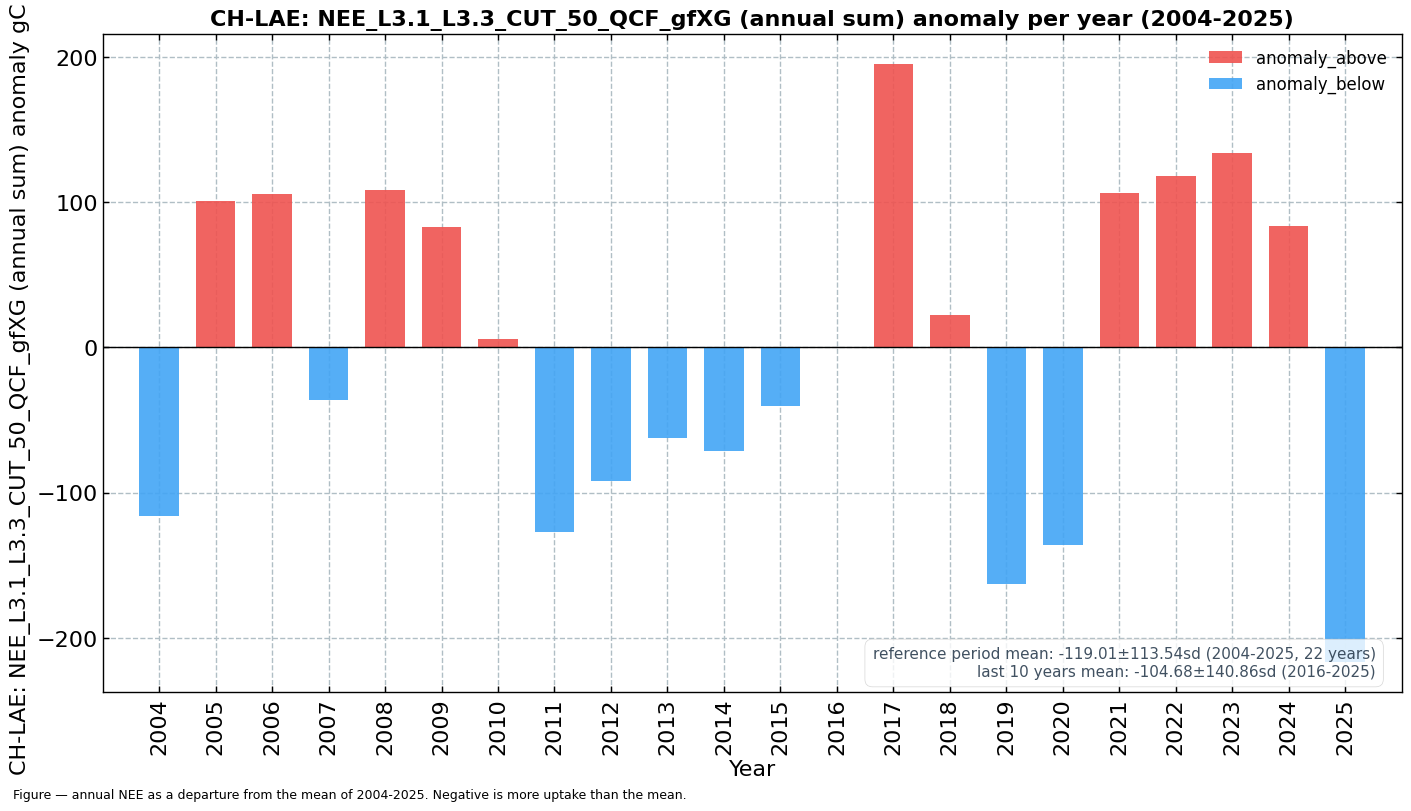

In [35]:
_anomalies_year = LongtermAnomaliesYear(series=yt.rename(varname),
                                        series_label=f"CH-LAE: {varname} (annual sum)",
                                        series_units=units_sum,
                                        reference_start_year=REFERENCE_START_YEAR,
                                        reference_end_year=REFERENCE_END_YEAR)
_anomalies_year.plot()
figcap(_anomalies_year.fig,
       f"annual NEE as a departure from the mean of {REFERENCE_START_YEAR}-{REFERENCE_END_YEAR}. "
       f"Negative is more uptake than the mean.")

## Trends

A trend over the whole record crosses the change of analyser. It is therefore given three ways:
over all years, over the LI-7200 years alone, and with a step at 2016 removed, so that a trend
carried by the step alone can be told apart.

### 📋 Table: trends of the annual sums

In [36]:
def _trend_row(s):
    _fit = trend(s.dropna())
    return {f"trend ({units_sum}/decade)": _fit['slope'], "lower 95 %": _fit['low'], "upper 95 %": _fit['high'],
            "p": _fit['pvalue'], "years": int(s.notna().sum())}


_rows = {}
for _c in [f"NEE ({units_sum})", "GPP (NT)", "RECO (NT)"]:
    _s = annual[_c]
    _rows[(_c, f"all years, {FIRST_YEAR}-{LAST_YEAR}")] = _trend_row(_s)
    _rows[(_c, f"LI-7200 years, 2016-{LAST_YEAR}")] = _trend_row(_s.loc[2016:])
    _rows[(_c, "all years, step at 2016 removed")] = _trend_row(
        _s - annual.groupby('analyser')[_c].transform('mean') + _s.mean())
trends = pd.DataFrame.from_dict(_rows, orient='index')
trends.index.names = ['flux', 'years']
display(styled(trends, caption="Theil-Sen trends of the annual sums with their 95 % interval and Kendall "
                               "p. Removing the step subtracts each analyser period's own mean, so only "
                               "the trend within the periods remains",
               fmt={c: ("{:.4f}" if c == "p" else "{:.0f}" if c == "years" else "{:+.1f}") for c in trends.columns},
               subset=[f"trend ({units_sum}/decade)"], cmap='RdBu_r', center=True))

Table — Theil-Sen trends of the annual sums with their 95 % interval and Kendall p. Removing the
step subtracts each analyser period's own mean, so only the trend within the periods remains



### 📊 Plot: annual sums and their trends

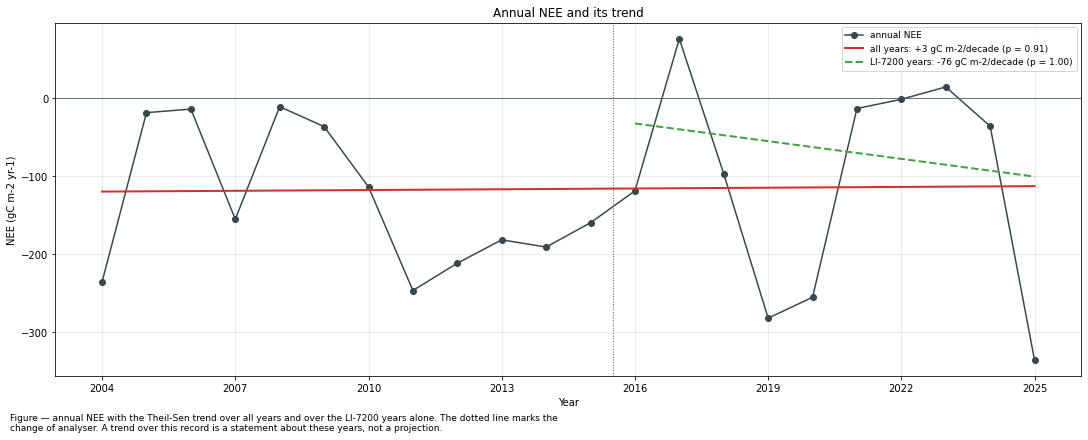

In [37]:
fig, ax = plt.subplots(figsize=(15, 6), dpi=72, layout="constrained")
ax.plot(yt.index, yt, marker='o', color='#37474F', lw=1.5, label="annual NEE")
_fit = trend(yt)
ax.plot(_fit['fit'].index, _fit['fit'], color='#D32F2F', lw=2,
        label=f"all years: {_fit['slope']:+.0f} {units_sum}/decade (p = {_fit['pvalue']:.2f})")
_fit72 = trend(yt.loc[2016:])
ax.plot(_fit72['fit'].index, _fit72['fit'], color='#43A047', lw=2, ls='--',
        label=f"LI-7200 years: {_fit72['slope']:+.0f} {units_sum}/decade (p = {_fit72['pvalue']:.2f})")
ax.axhline(0, color='#455A64', lw=0.8)
ax.axvline(2015.5, color='#616161', lw=1, ls=':')
ax.set_xlabel("Year")
ax.set_ylabel(f"NEE ({units_sum} yr-1)")
ax.set_title("Annual NEE and its trend")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
year_axis(ax)
figcap(fig, "annual NEE with the Theil-Sen trend over all years and over the LI-7200 years alone. The "
            "dotted line marks the change of analyser. A trend over this record is a statement about "
            "these years, not a projection.")
fig.show()

</br>

# Cumulative plot

## 📊 Plot: cumulative NEE per year

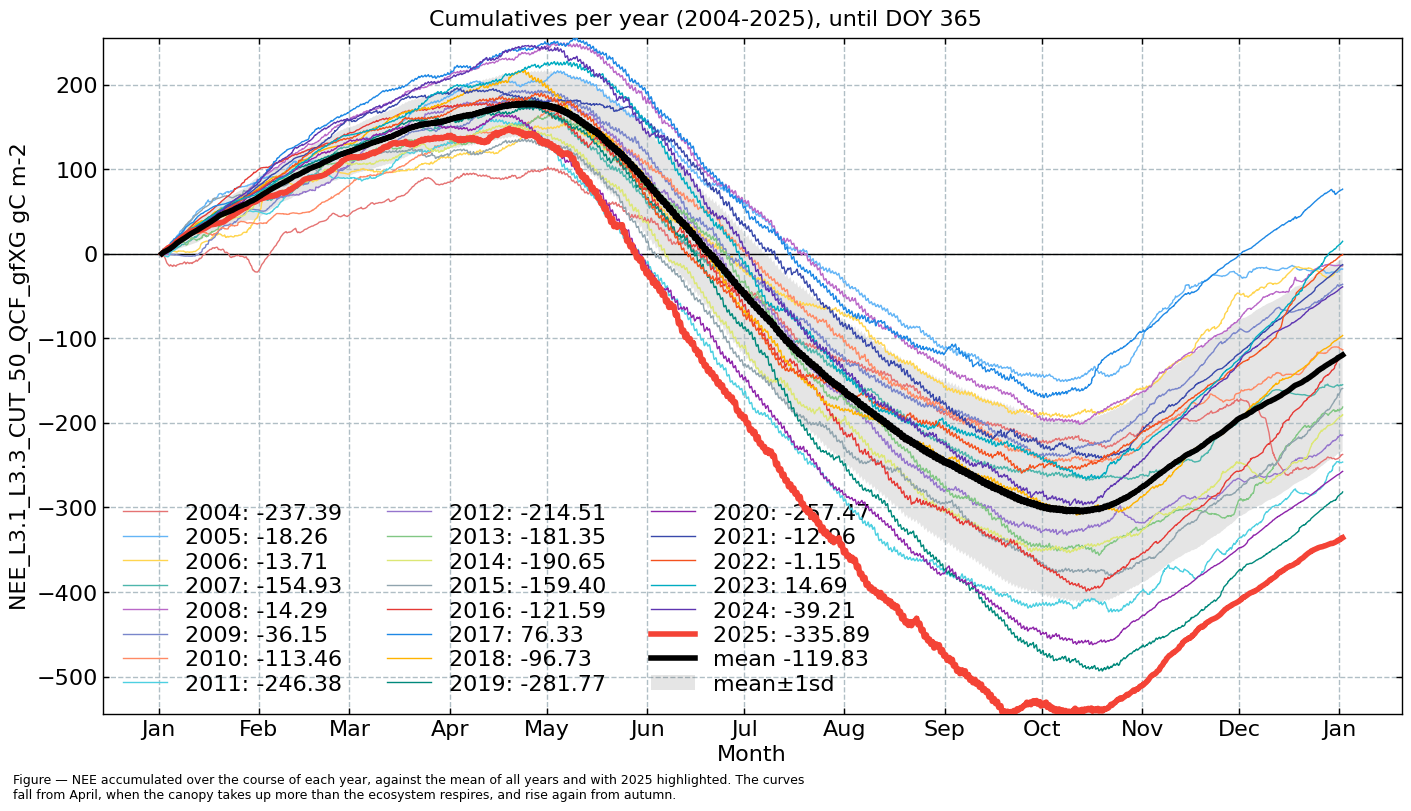

In [38]:
_cumulative = CumulativeYear(
    series=(series * UMOL_TO_GC).rename(varname),
    series_units=units_sum,
    start_year=FIRST_YEAR,
    end_year=LAST_YEAR,
    show_reference=True,
    excl_years_from_reference=None,
    highlight_year=LAST_YEAR)
_cumulative.plot(highlight_year_color='#F44336')
figcap(_cumulative.fig,
       f"NEE accumulated over the course of each year, against the mean of all years and with "
       f"{LAST_YEAR} highlighted. The curves fall from April, when the canopy takes up more than the "
       f"ecosystem respires, and rise again from autumn.")

</br>

# Distributions

## 📊 Plot: distribution per year

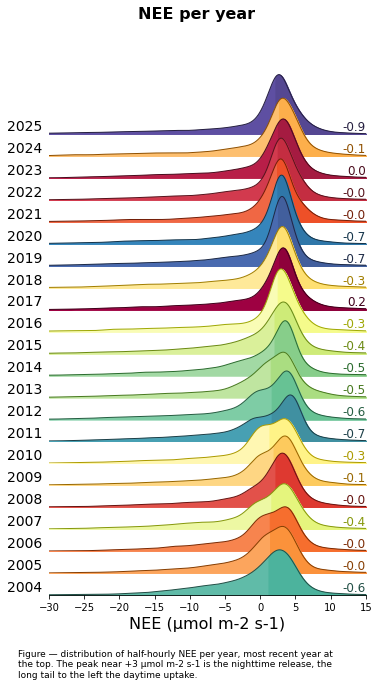

In [39]:
rp = dv.plotting.RidgeLinePlot(series=series)
rp.plot(
    how='yearly',
    kd_kwargs=None,  # params from scikit KernelDensity as dict
    xlim=[-30, 15],  # min/max as list
    ylim=[0, 0.25],  # min/max as list
    hspace=-0.8,  # overlap between years
    fig_width=5,
    fig_height=9,
    shade_percentile=0.5,
    show_mean_line=False,
    format_style=dv.plotting.FormatStyle(xlabel=xlabel, title=f"{var} per year"),
    fig_dpi=72,
    showplot=True,
    ascending=False
)
figcap(rp.fig, f"distribution of half-hourly NEE per year, most recent year at the top. The peak "
               f"near +3 {units} is the nighttime release, the long tail to the left the daytime "
               f"uptake.")

</br>

# End of notebook

In [40]:
dt_string = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
print(f"Finished. {dt_string}")

Finished. 2026-10-29 15:19:13
